# Trabalho Prático de Mineração de Dados — Fase 2
## Utilização de LLMs e Análise Comparativa com Diretrizes de IA Responsável

**Disciplina:** Mineração de Dados  
**Grupo:** Grupo 13 - Arthur Faria (2024013915), Felipe Pereira (2024080051), Giordano Liporati (2023027963), João Vaz (2023099166)  
**Dataset:** Spotify Tracks Dataset - https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset

**Tarefa de mineração:** Classificação  
**Data da entrega:** 24/05/2026


# 0. Controle da entrega e rastreabilidade

Esta seção registra informações mínimas para tornar o trabalho rastreável e auditável.

| Item | Valor |
|---|---|
| Nome do dataset | Spotify Tracks Dataset |
| Link público do dataset | https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset |
| Número de linhas | 114.000 |
| Número de colunas | 21 |
| Tarefa de mineração | Classificação |
| LLM usada na Trilha A | ChatGPT |
| LLM usada na Trilha B | ChatGPT |
| Link da conversa — Trilha A | Ver lista detalhada abaixo |
| Link da conversa — Trilha B | Ver lista detalhada abaixo |

**Links das interações (Trilha A - Baseline):**
* **Business Understanding:** https://chatgpt.com/share/6a260b8e-f958-83e9-9a70-7a92d0099c6e
* **Data Preparation:** https://chatgpt.com/share/6a26de77-fef8-83e9-8911-94d09e6bbf19
* **Modeling:** https://chatgpt.com/share/6a2c439c-8edc-83e9-9359-dddfba3f62e4

**Links das interações (Trilha B - Guiada):**
* **Business Understanding:** https://chatgpt.com/share/6a260bba-647c-83e9-8647-a6d13e53a57a
* **Data Preparation:** https://chatgpt.com/share/6a26df0c-8e6c-83e9-9177-4ff60f82fa31
* **Modeling:** https://chatgpt.com/share/6a2c4365-bca0-83e9-b7bd-3a28b1f594d4

## Diretrizes de IA responsável escolhidas

| Diretriz | Justificativa da escolha | Como será explicitada na Trilha B |
|---|---|---|
| **Eficiência e escalabilidade** | O dataset possui um volume grande de instâncias (~92 mil linhas úteis). Algoritmos de classificação muito complexos (como SVM com kernel não-linear) ou buscas exaustivas de hiperparâmetros (GridSearch) podem gerar um gargalo computacional imenso durante o treinamento. | Exigiremos no prompt que a LLM recomende algoritmos de treinamento rápido e escalável (como frameworks de gradiente estilo LightGBM ou XGBoost) e estratégias de otimização de hiperparâmetros mais eficientes (ex: RandomizedSearchCV). |
| **Usabilidade e acessibilidade** | Modelos preditivos frequentemente agem como "caixas-pretas", retornando apenas a predição final. Para que diretores e produtores musicais confiem na classificação de "Hit" vs "Nicho", o modelo precisa ser interpretável e visualmente claro. | Solicitaremos no prompt que a LLM proponha métodos para explicar as previsões (ex: extração e plotagem de *Feature Importance*) e avaliações que vão além da matemática, usando Matrizes de Confusão intuitivas para mostrar os falsos positivos/negativos. |



In [1]:
# Configurações iniciais do notebook
# Esta célula centraliza imports e parâmetros gerais.
# O grupo deve adaptar os caminhos, nomes de colunas e tipo de tarefa.

import os
import time
import json
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Caminho para o dataset.
# Exemplos:
# DATA_PATH = "dados/dataset.csv"
# DATA_PATH = "/content/dataset.csv"
DATA_PATH = "spotify-tracks-dataset.csv"

# Tipo de tarefa do TP.
# Opções sugeridas:
# - "padroes_frequentes"
# - "agrupamento"
# - "classificacao"
TASK_TYPE = "classificacao"

# Coluna-alvo, se aplicável.
# Para padrões frequentes ou agrupamento, normalmente pode ser None.
TARGET_COLUMN = "is_hit"  # criação da coluna-alvo "is_hit" com base na popularidade

# Coluna ou conjunto de colunas usadas para gerar transações, se o TP for de padrões frequentes.
TRANSACTION_COLUMN = "[INSERIR_COLUNA_DE_TRANSACOES]"

print("Configuração carregada.")
print(f"Tarefa definida: {TASK_TYPE}")


Configuração carregada.
Tarefa definida: classificacao


# 1. Business Understanding

## 1.1 Descrição do problema de negócio

- **Contexto:** A indústria fonográfica e as plataformas de *streaming* operam em um mercado altamente saturado, onde milhares de músicas são lançadas diariamente. O sucesso comercial de uma faixa frequentemente parece imprevisível, dependendo de fatores externos complexos.
- **Problema:** É possível prever se uma música será um sucesso de mercado ("Hit") ou se ficará restrita a um público menor ("Nicho") analisando estritamente suas características acústicas (ritmo, energia, acústica), antes mesmo de qualquer investimento em divulgação?
- **Possíveis interessados:** Gravadoras, produtores musicais, curadores de *playlists* e equipes de marketing de plataformas como o Spotify.
- **Decisões apoiadas pela análise:** Um modelo preditivo robusto permite direcionar orçamentos de marketing com maior segurança, identificar faixas com potencial viral dentro de álbuns recém-lançados e ajudar produtores a ajustarem a mixagem de uma música para se alinhar ao padrão sonoro do que está em alta no mercado.
- **Limitações iniciais conhecidas:** O sucesso comercial (`popularity`) não depende exclusivamente da sonoridade; fatores como a fama prévia do artista e o orçamento de marketing da gravadora influenciam fortemente, o que introduzirá "ruído" inevitável no modelo. Além disso, ao binarizar a popularidade (ex: limiar de 50), enfrentaremos um provável desbalanceamento de classes, exigindo métricas de avaliação além da acurácia simples.


## 1.2 Objetivo do dataset, origem e características gerais

### Objetivo do dataset
O dataset captura as métricas e *features* de áudio de milhares de músicas, calculadas pelos algoritmos de extração da própria API do Spotify. O propósito é permitir a análise quantitativa da estrutura musical (acústica, instrumentalidade, positividade, andamento) e sua relação com a popularidade global da faixa na plataforma.

### Origem dos dados
Os dados foram extraídos da API oficial do Spotify pelo usuário Yash Dev e disponibilizados publicamente na plataforma Kaggle.

Link público: https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset

### Características do dataset

| Coluna | Tipo esperado | Descrição | Relevância para a tarefa |
|---|---|---|---|
| **popularity** | Numérico contínuo | Índice de sucesso da música no Spotify (0 a 100). | **Alvo base.** Será convertida na variável-alvo categórica binária `is_hit`. |
| **danceability** | Numérico contínuo | O quão adequada a faixa é para dançar. | **Alta.** Fator historicamente forte em músicas pop/comerciais. |
| **energy** | Numérico contínuo | Medida de intensidade, peso e atividade da faixa. | **Alta.** Crucial para distinguir faixas calmas de potenciais "hits" de rádio/festa. |
| **valence** | Numérico contínuo | A "positividade" musical transmitida. | **Alta.** Captura o humor da faixa, influenciando a aceitação do público. |
| **acousticness** | Numérico contínuo | Probabilidade de a música ser acústica. | **Média.** Pode penalizar faixas muito orgânicas frente ao mercado eletrônico atual. |
| **instrumentalness** | Numérico contínuo | Probabilidade de ausência de vocais na música. | **Alta.** O mercado de massa tende a rejeitar faixas 100% instrumentais. |
| **track_genre** | Categórico | Gênero oficial da faixa. | **Baixa/Média.** Pode causar vazamento de dados (*data leakage*); idealmente avaliada com cautela ou removida. |

### Relação com o problema de negócio
Este dataset é o ideal para a tarefa de Classificação. Ele possui tanto as variáveis preditoras contínuas quanto a "resposta certa" (a popularidade atual da música), permitindo que algoritmos de *Machine Learning* encontrem o padrão sonoro que mais se aproxima do gosto das massas.

## 1.3 Diretrizes selecionadas e hipótese experimental

### Diretrizes selecionadas

| Diretriz | Por que é pertinente ao problema? | Possível efeito esperado na solução da LLM |
|---|---|---|
| **Eficiência e escalabilidade** | O treinamento de modelos de classificação em uma base de ~144 mil instâncias pode ser demorado, especialmente durante a busca de hiperparâmetros (ex: otimização de florestas de decisão). Algoritmos muito pesados atrasam o ciclo de experimentação. | Espera-se que a LLM proponha *frameworks* baseados em gradiente rápidos (como LightGBM) e métodos de otimização de parâmetros mais eficientes (como `RandomizedSearchCV` em vez do exaustivo `GridSearchCV`). |
| **Usabilidade e acessibilidade** | Diretores musicais e produtores não confiam em algoritmos "caixa-preta". Dizer apenas que uma música será um hit não basta; o modelo precisa explicar o porquê em linguagem de negócios. | Espera-se que a LLM recomende a plotagem clara de Matrizes de Confusão e a extração da Importância de Atributos (*Feature Importance*), para responder perguntas como: "Aumentar a *energia* da faixa aumenta as chances de hit?". |

### Hipótese experimental

Esperamos que, ao explicitar as diretrizes de **Eficiência/Escalabilidade** e **Usabilidade/Acessibilidade**, a LLM abandone recomendações acadêmicas padronizadas em favor de um *pipeline* operacional moderno e focado em negócios. 

Na trilha de referência (baseline), prevemos que a IA sugira algoritmos classicamente ensinados mas de alto custo computacional em bases grandes (como SVM com kernel não-linear), além de limitar a avaliação metodológica a métricas globais simples (como Acurácia), sem se preocupar com interpretabilidade. Na trilha guiada, hipotetizamos que a IA ajustará sua proposta: exigirá modelos robustos e velozes (*Ensembles/Tree-based*), sugerirá métricas preparadas para classes desbalanceadas (*Precision*, *Recall*, *ROC-AUC*) e, sobretudo, detalhará técnicas visuais de explicabilidade (*Feature Importance*) para que os produtores musicais compreendam quais atributos acústicos ditam o sucesso de uma faixa.


## 1.4 Interações com LLM — Business Understanding

### Trilha A — baseline

**Modelo utilizado:** ChatGPT-5.3  
**Data de acesso:** 07/06/2026  
**Link da conversa:** https://chatgpt.com/share/6a260b8e-f958-83e9-9a70-7a92d0099c6e 
**Subtarefa:** obter apoio para formular o Business Understanding e planejar o pipeline de classificação.

#### Prompt principal — baseline

```text
Estou fazendo um trabalho prático de Mineração de Dados com o "Spotify Tracks Dataset". A tarefa é Classificação.
O objetivo é prever o sucesso comercial de uma música (classificando-a em "Hit" ou "Nicho") usando a variável "popularity" binarizada e baseando-se estritamente nas features acústicas contínuas da faixa (danceability, energy, valence, etc).

Ajude-me a formular o "Business Understanding". Descreva de forma geral como devemos estruturar nosso pipeline de análise, como tratar os dados e quais algoritmos e métricas deveríamos usar para classificar essas faixas.
```

#### Síntese da resposta da LLM

A resposta da LLM apresentou um roteiro de classificação padrão e teoricamente correto, definindo o problema como Aprendizado Supervisionado Binário ("Hit" vs "Nicho"). Sugeriu um *pipeline* clássico: Análise Exploratória, padronização (StandardScaler), divisão estratificada e validação cruzada. No entanto, a sugestão de algoritmos foi genérica, listando opções de altíssimo custo computacional para bases de quase 100 mil linhas (como KNN e SVM) sem alertar para o gargalo de tempo. A interpretação limitou-se à avaliação de métricas globais (F1-Score, ROC-AUC) e à observação básica de importância de variáveis em modelos de árvore, sem aprofundar em como comunicar esses resultados aos tomadores de decisão.

---

### Trilha B — guiada por diretrizes

**Modelo utilizado:** ChatGPT-5.3   
**Data de acesso:** 07/06/2026  
**Link da conversa:** https://chatgpt.com/share/6a260bba-647c-83e9-8647-a6d13e53a57a
**Subtarefa:** obter apoio para formular o Business Understanding considerando as diretrizes escolhidas.

#### Prompt principal — guiado

```text
Estou fazendo um trabalho prático de Mineração de Dados com o "Spotify Tracks Dataset". A tarefa é Classificação.
O objetivo é prever o sucesso comercial de uma música (classificando-a em "Hit" ou "Nicho") usando a variável "popularity" binarizada, baseando-se apenas nas features acústicas contínuas da faixa.

Ajude-me a elaborar o "Business Understanding" estruturando o pipeline e os métodos.

Crucial: Você deve seguir estritamente as seguintes diretrizes de IA Responsável:
1. Eficiência e Escalabilidade: O dataset é volumoso para ciclos de treinamento exaustivos. Proponha abordagens para otimização de hiperparâmetros e algoritmos que não gerem gargalos computacionais no treinamento/inferência.
2. Usabilidade e Acessibilidade: O modelo não pode ser uma "caixa-preta". Produtores musicais precisam entender O PORQUÊ da predição. Proponha ferramentas visuais e explicabilidade de forma didática e acionável para os negócios.
```

#### Síntese da resposta da LLM

A resposta da LLM foi altamente estratégica e guiada pelas diretrizes. Para **Eficiência e Escalabilidade**, a IA vetou algoritmos pesados (como SVM com kernel RBF) e buscas exaustivas, sugerindo o `LightGBM` ou `HistGradientBoosting` combinados com `RandomizedSearchCV` e *Early Stopping* para acelerar o treinamento. Para **Usabilidade e Acessibilidade**, a LLM focou na abertura da "caixa-preta": além da Importância de Variáveis global, ela introduziu o uso da biblioteca **SHAP** (*SHapley Additive Explanations*) para interpretabilidade local. Ela demonstrou como traduzir a previsão de uma única música para um produtor (ex: "a música foi um hit porque a *danceability* alta contribuiu positivamente"), tornando o modelo altamente acionável.

## 1.5 Análise crítica das trilhas — Business Understanding

| Critério | Trilha A — baseline | Trilha B — guiada | Diferença observada |
|---|---|---|---|
| **Clareza do problema** | Boa. Definiu a tarefa de prever "Hit vs Nicho". | Excelente. Conectou a previsão a ações de negócios (alocação de marketing, priorização). | A Trilha B expandiu o escopo de um mero modelo preditivo para uma ferramenta de suporte à decisão. |
| **Relação com o dataset** | Listou corretamente as variáveis a serem mantidas e removidas. | Listou as variáveis e alertou contra o *Data Leakage* (vazamento de dados). | Ambas compreenderam o dataset, mas a B focou na integridade do treinamento. |
| **Consideração das diretrizes** | Não aplicável (baseline). | Atendeu plenamente, dividindo a proposta em seções dedicadas à Eficiência e Usabilidade. | A Trilha B transformou as diretrizes no núcleo do *pipeline* metodológico. |
| **Identificação de riscos** | Omitiu os riscos de sobrecarga computacional no treinamento. | Alertou contra o uso de `GridSearch`, Redes Neurais profundas e SVM para esta volumetria. | A Trilha A falhou em reconhecer o impacto operacional do tamanho da base; a Trilha B propôs contenções claras. |
| **Qualidade da justificativa** | Justificativas acadêmicas de dicionário (ex: "KNN captura relações não lineares"). | Justificativas pragmáticas (ex: "Random Search explora melhor o espaço com menor custo"). | A Trilha B justificou as escolhas com base no binômio custo/benefício, essencial em ambientes de produção. |
| **Erros ou omissões** | Omitiu o risco de lentidão extrema ao aplicar KNN/SVM em ~144 mil instâncias. | Não apresentou erros técnicos; abordagens sugeridas são estado-da-arte. | Seguir a Trilha A cegamente resultaria em horas de tempo ocioso aguardando o treinamento de modelos ineficientes. |

### Síntese crítica

A hipótese experimental formulada pelo grupo foi fortemente validada. A inserção das diretrizes de **Eficiência/Escalabilidade** e **Usabilidade/Acessibilidade** produziu evidências concretas de melhoria no planejamento metodológico do modelo de Classificação.

Em termos de eficiência, a Trilha A recomendou um leque genérico de algoritmos que incluía SVM e KNN. Para um *dataset* de aproximadamente 144.000 linhas e múltiplas dimensões contínuas, calcular matrizes de distância (KNN) ou otimizar hiperplanos não lineares (SVM) causaria severos gargalos computacionais. A Trilha B corrigiu ativamente esse risco metodológico: baniu o SVM, substituiu o método de otimização exaustivo (`GridSearch`) pelo `RandomSearch`, recomendou a parada antecipada (*Early Stopping*) e apontou diretamente para *frameworks* modernos de alta velocidade focados em dados tabulares, como o `LightGBM`.

A maior distinção, contudo, ocorreu na Usabilidade. A Trilha A limitou a interpretação do modelo ao cálculo da Acurácia e ROC-AUC. A Trilha B compreendeu que métricas matemáticas não explicam o resultado para o usuário de negócios (produtores musicais). Para quebrar a barreira da "caixa-preta", a resposta guiada propôs o uso de **SHAP values**, fornecendo uma arquitetura para interpretabilidade local. Isso altera a entrega do projeto: passamos a ter a capacidade de isolar uma única música e explicar visualmente aos interessados por que o algoritmo previu que ela será um sucesso comercial (ex: apontando que a alta energia daquela faixa específica puxou a predição para cima). Essa adição elevou drasticamente a utilidade prática do modelo planejado.

# 2. Data Understanding & Data Preparation


In [2]:
# Carregamento do dataset
# Esta célula deve ser adaptada de acordo com o formato do arquivo.

def carregar_dataset(caminho: str) -> pd.DataFrame:
    # Carrega um dataset a partir de um arquivo CSV, Excel, JSON ou Parquet.
    # Adapte esta função se o dataset estiver em outro formato.
    if caminho == "[INSERIR_CAMINHO_DO_ARQUIVO]":
        raise ValueError("Substitua DATA_PATH pelo caminho real do dataset.")

    caminho_path = Path(caminho)

    if not caminho_path.exists():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho}")

    if caminho_path.suffix.lower() == ".csv":
        return pd.read_csv(caminho_path)
    elif caminho_path.suffix.lower() in [".xlsx", ".xls"]:
        return pd.read_excel(caminho_path)
    elif caminho_path.suffix.lower() == ".json":
        return pd.read_json(caminho_path)
    elif caminho_path.suffix.lower() == ".parquet":
        return pd.read_parquet(caminho_path)
    else:
        raise ValueError("Formato não tratado neste modelo. Adapte a função carregar_dataset.")

# Exemplo de uso:
df = carregar_dataset(DATA_PATH)
print("Dataset carregado com sucesso.")
print(f"Número de linhas: {df.shape[0]}")
print(f"Número de colunas: {df.shape[1]}")
display(df.head())


Dataset carregado com sucesso.
Número de linhas: 114000
Número de colunas: 22


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
# Verificação mínima das restrições do dataset
# A especificação exige dataset público, com pelo menos 1000 linhas e 4 colunas.
# O link público deve ser documentado em Markdown; aqui validamos apenas dimensões.

def verificar_restricoes_dataset(df: pd.DataFrame) -> None:
    n_linhas, n_colunas = df.shape

    print("Verificação das dimensões do dataset")
    print(f"- Linhas: {n_linhas}")
    print(f"- Colunas: {n_colunas}")

    if n_linhas < 1000:
        print("ATENÇÃO: o dataset possui menos de 1000 linhas.")
    else:
        print("OK: o dataset possui pelo menos 1000 linhas.")

    if n_colunas < 4:
        print("ATENÇÃO: o dataset possui menos de 4 colunas.")
    else:
        print("OK: o dataset possui pelo menos 4 colunas.")

# Executar após carregar o dataset:
verificar_restricoes_dataset(df)


Verificação das dimensões do dataset
- Linhas: 114000
- Colunas: 22
OK: o dataset possui pelo menos 1000 linhas.
OK: o dataset possui pelo menos 4 colunas.


In [4]:
# Exploração inicial
# Esta célula gera uma visão geral do dataset.
# O grupo deve interpretar os resultados em uma célula Markdown logo abaixo.

def resumo_inicial(df: pd.DataFrame) -> pd.DataFrame:
    resumo = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "n_nulos": df.isna().sum(),
        "perc_nulos": (df.isna().mean() * 100).round(2),
        "n_unicos": df.nunique(dropna=True)
    })

    return resumo.sort_values(by="perc_nulos", ascending=False)

# Exemplo de uso:
resumo = resumo_inicial(df)
display(resumo)


,tipo,n_nulos,perc_nulos,n_unicos
Unnamed: 0.1,int64,0,0.0,114000
Unnamed: 0,int64,0,0.0,114000
track_id,str,0,0.0,89741
artists,str,1,0.0,31437
album_name,str,1,0.0,46589
track_name,str,1,0.0,73608
popularity,int64,0,0.0,101
duration_ms,int64,0,0.0,50697
explicit,bool,0,0.0,2
danceability,float64,0,0.0,1174


In [5]:
# Estatísticas descritivas
# O objetivo é separar análise de variáveis numéricas e categóricas.

def estatisticas_descritivas(df: pd.DataFrame):
    numericas = df.select_dtypes(include=np.number)
    categoricas = df.select_dtypes(exclude=np.number)

    print("Colunas numéricas:", list(numericas.columns))
    print("Colunas não numéricas:", list(categoricas.columns))

    if len(numericas.columns) > 0:
        print("\nEstatísticas descritivas — variáveis numéricas")
        display(numericas.describe().T)

    if len(categoricas.columns) > 0:
        print("\nEstatísticas descritivas — variáveis categóricas/textuais")
        display(categoricas.describe().T)

# Exemplo de uso:
# estatisticas_descritivas(df)


## 2.1 Exploração inicial — interpretação

O *Spotify Tracks Dataset* possui uma estrutura robusta composta por exatamente 114.000 linhas e 21 colunas, apresentando uma mistura bem definida de tipos de atributos. Entre eles, destacam-se variáveis textuais (como `track_id`, `artists`, `album_name`, `track_name` e `track_genre`), numéricas inteiras (`popularity`, `duration_ms`, `key` e `time_signature`), numéricas contínuas flutuantes (como `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence` e `tempo`) e uma única variável booleana (`explicit`). Em termos de integridade, o conjunto de dados é considerado extremamente limpo, registrando apenas uma quantidade ínfima de valores ausentes (apenas uma linha com campos nulos em `artists`, `album_name` e `track_name`), o que torna a imputação quase desnecessária, bastando a remoção dessa linha específica.

Ao analisar o comportamento e a cardinalidade das variáveis, identificam-se metadados textuais com muitos valores distintos, como `track_name` (mais de 73.000 nomes) e `album_name` (mais de 46.000 álbuns), que funcionam como o contexto descritivo da obra. O principal identificador unívoco é a coluna `track_id`, correspondente à chave primária da faixa na API do Spotify. Sob a perspectiva de atributos sensíveis e éticos, embora o conjunto trate de produções artísticas e não de dados pessoais protegidos por legislações como a LGPD, as variáveis `explicit` (presença de conteúdo explícito) e os metadados de `artists` e `track_genre` podem introduzir vieses sociais ou mercadológicos na classificação biológica do sucesso, pois certos gêneros ou artistas renomados naturalmente acumulam maior tração comercial independentemente de sua estrutura acústica inerente.

Para atender estritamente ao escopo da tarefa, que visa prever o sucesso comercial baseado nas características sonoras da música, as variáveis de real relevância são exclusivamente as features acústicas contínuas e os componentes estruturais de áudio. Isso engloba `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence` e `tempo`, além dos fatores categóricos numéricos `key` e `mode`. A variável `popularity` atuará estritamente na fase de preparação para dar origem ao rótulo binário alvo ("Hit" versus "Nicho"). Para preparar os dados adequadamente para a modelagem, todas as colunas de texto descritivo e identificadores devem ser descartadas, prevenindo que o classificador decore padrões nominais em vez de aprender as propriedades de áudio. Além disso, as features contínuas de escalas amplas e díspares, como `tempo` (medido em BPM) e `loudness` (medido em decibéis negativos), exigirão a aplicação de uma padronização (Z-score) ou normalização (Min-Max) para alinhar sua magnitude com variáveis que já nascem restritas ao intervalo entre 0 e 1, garantindo a estabilidade matemática de modelos baseados em distância ou gradiente.

Por fim, as limitações iniciais percebidas no conjunto de dados impõem desafios técnicos severos a serem mitigados ativamente. O primeiro grande obstáculo é a redundância massiva: o dataset contém dezenas de milhares de registros duplicados causados pela mesma música aparecer em álbuns diferentes, coletâneas ou lançamentos de rádio, o que exige uma limpeza rigorosa via remoção de duplicatas pelo par artista/música para evitar o vazamento de dados entre os conjuntos de treino e teste. Adicionalmente, a distribuição da variável `popularity` exibe uma distorção drástica com uma alta concentração de valores perfeitamente iguais a zero (músicas sem histórico de reprodução ou faixas fantasma), o que significa que o ponto de corte escolhido para a binarização gerará um desbalanceamento acentuado de classes (muito mais músicas de "Nicho" do que "Hits"). A limitação mais profunda, contudo, é a conceitual: ao tentar isolar o sucesso comercial estritamente dentro de atributos de áudio, desconsiderando investimentos de marketing, apelo visual e a popularidade prévia do artista, o modelo enfrentará uma sobreposição quase completa nas distribuições de densidade das classes, indicando que o teto de acurácia pode ser limitado e exigirá o monitoramento rigoroso por métricas robustas como F1-Score e a curva AUC-ROC em detrimento da acurácia geral.

### Relação com as diretrizes escolhidas

A diretriz de **Eficiência e Escalabilidade** se relaciona com a análise do volume de dados (114.000 linhas), da alta dimensionalidade e da cardinalidade extrema de colunas textuais como `track_name` e `album_name`. Ao identificar de antemão essa volumetria e a presença de milhares de categorias distintas, detecta-se gargalos operacionais antes da modelagem. No cenário de produção, processar textos massivos ou manter representações esparsas (como One-Hot Encoding para milhares de álbuns) tornaria o modelo excessivamente pesado, lento e caro para computar. A decisão de descartar metadados de alta cardinalidade e focar estritamente nas dezenas de features acústicas contínuas garante um modelo leve, cujo treinamento e inferência consomem menos recursos computacionais, permitindo que o sistema processe milhões de novas faixas em tempo real à medida que são lançadas na plataforma.

Por sua vez, a diretriz de **Usabilidade e Acessibilidade** reflete-se na análise dos tipos de atributos, na identificação de valores ausentes e, crucialmente, no tratamento da variável `popularity`. Para que uma IA seja verdadeiramente utilizável, o comportamento do modelo precisa ser intuitivo e livre de falhas geradas por dados corrompidos. Identificar a anomalia das músicas com popularidade zero e a necessidade de binarizar essa variável para "Hit" ou "Nicho" é o que torna o resultado final compreensível e útil para o negócio. Além disso, mapear as variáveis acústicas em escalas díspares (como `loudness` e `tempo`) e planejar sua padronização garante que a interface de entrada de dados seja acessível: o usuário final pode fornecer dados brutos e comuns da música sem que o modelo quebre ou entregue predições inconsistentes, gerando um sistema confiável e amigável para profissionais que não são da área técnica.


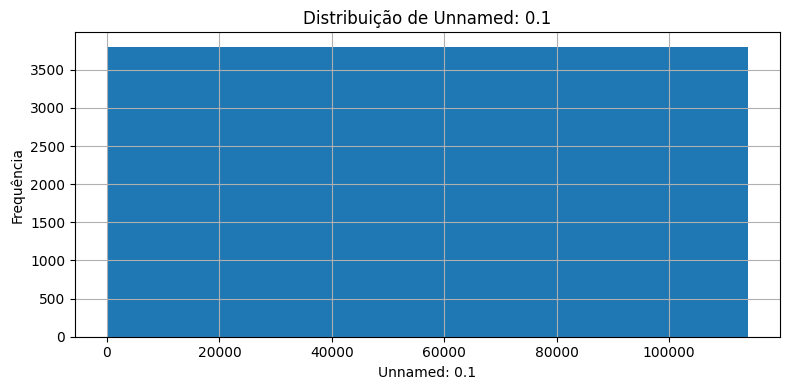

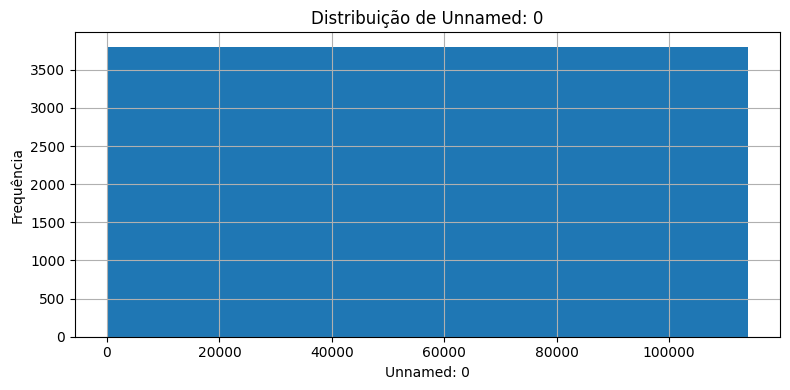

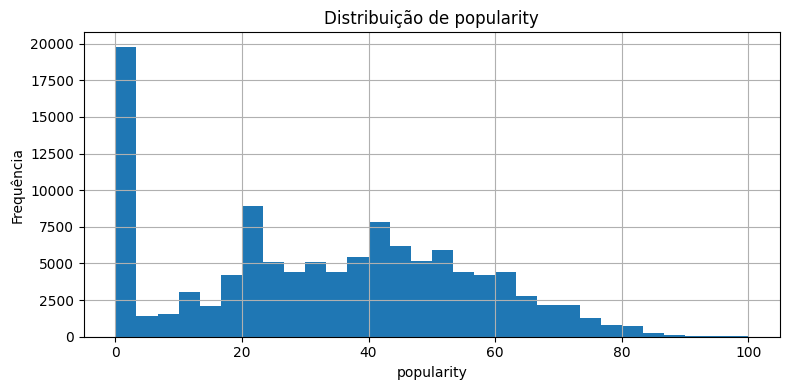

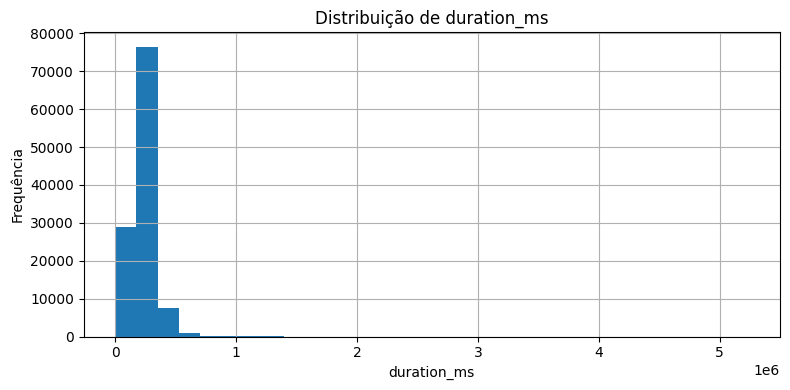

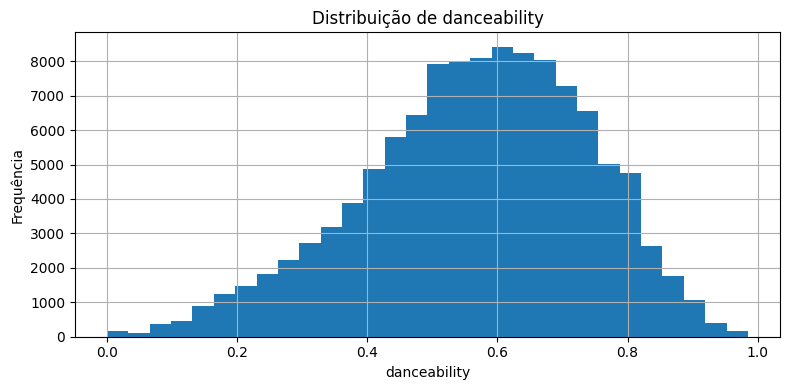

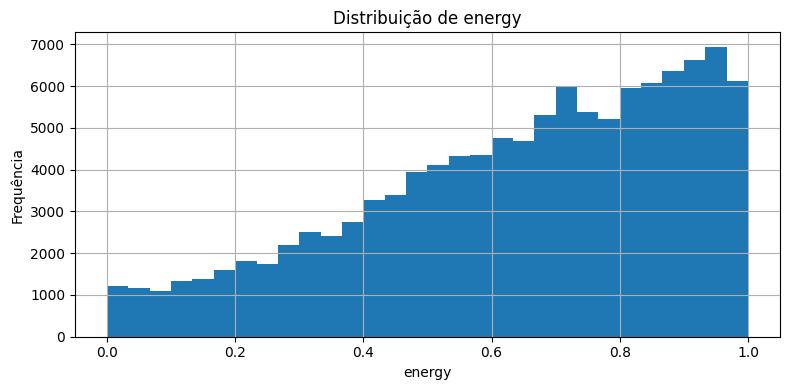

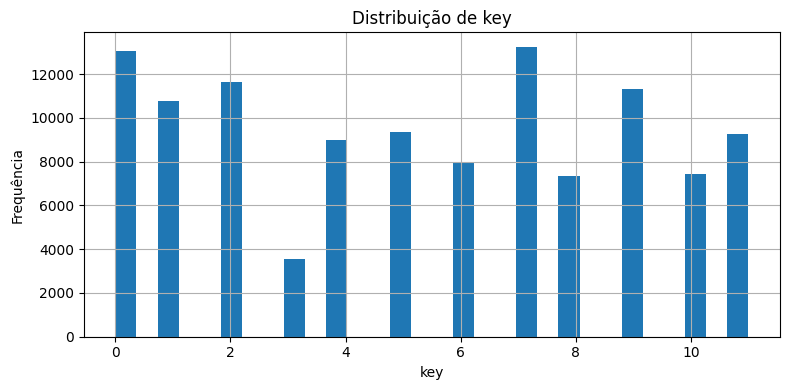

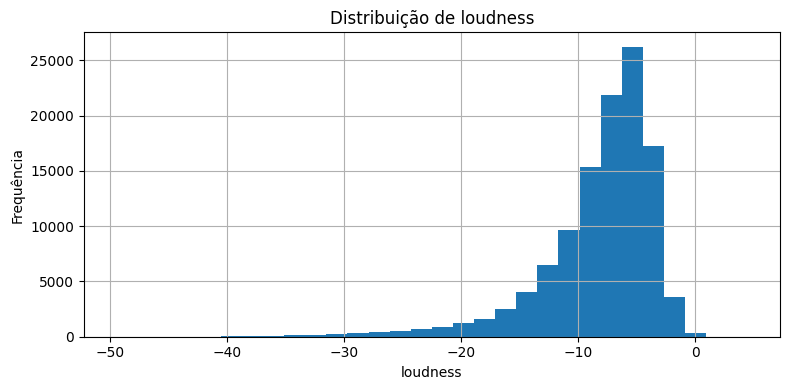

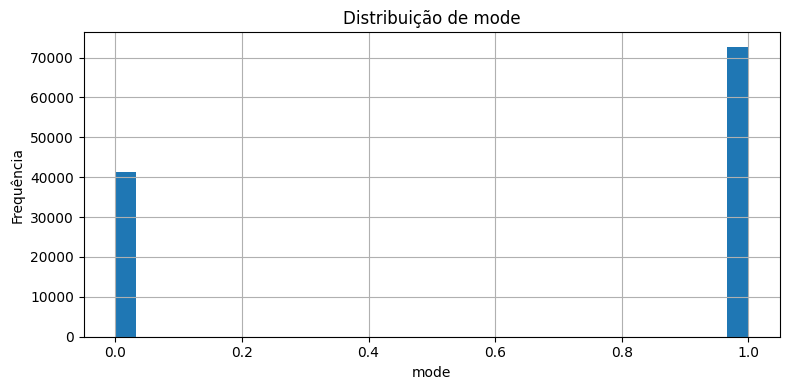

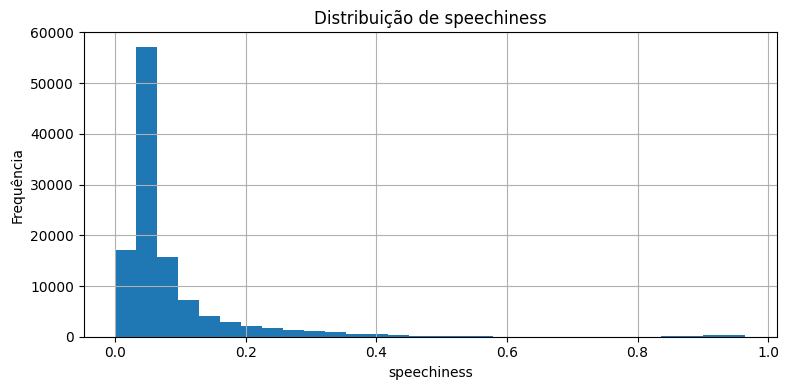

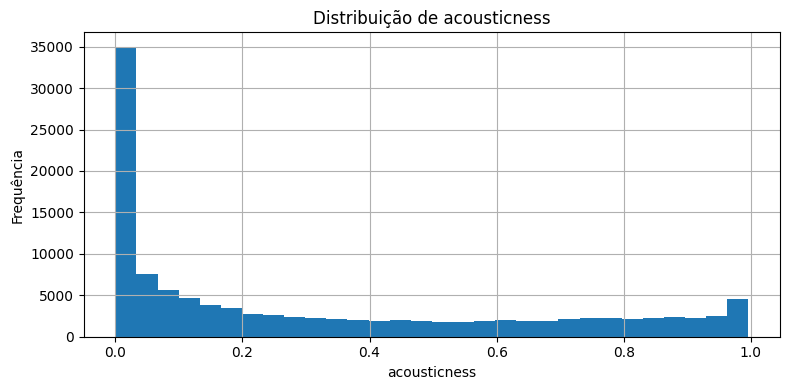

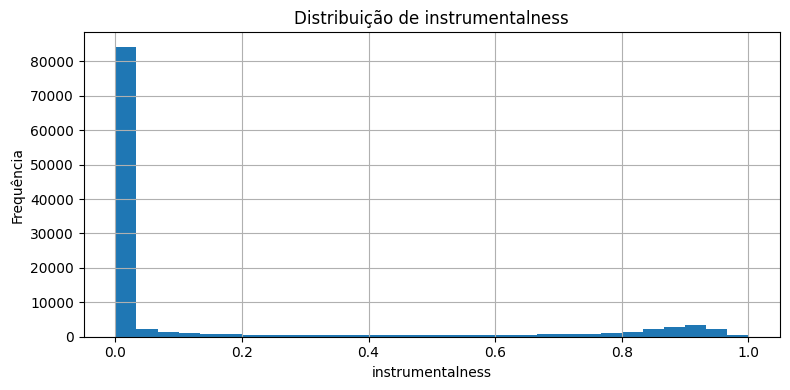

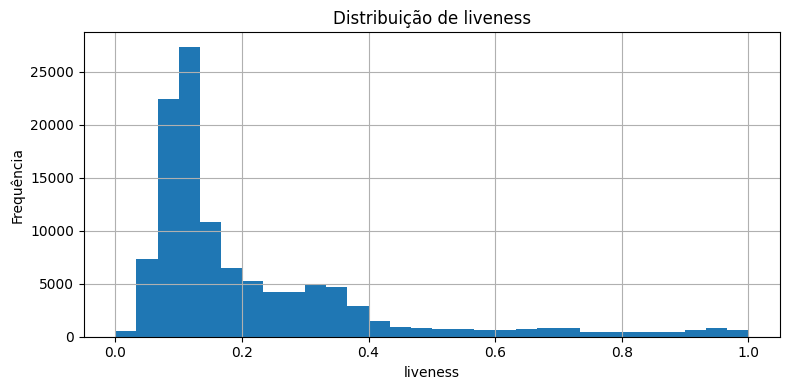

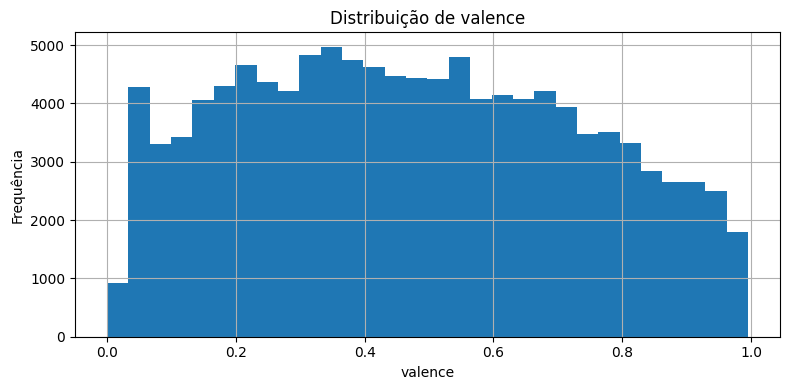

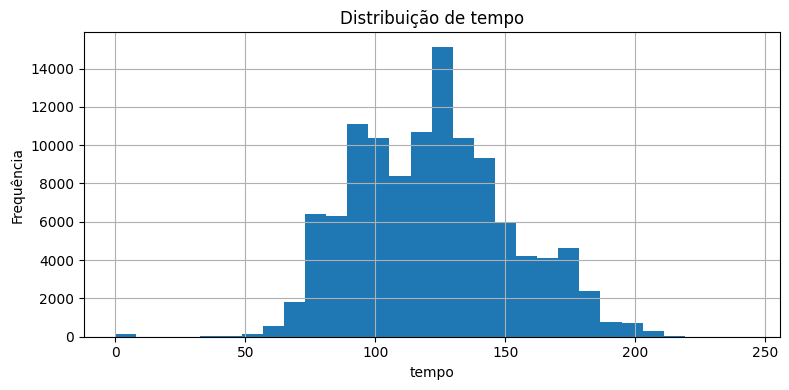

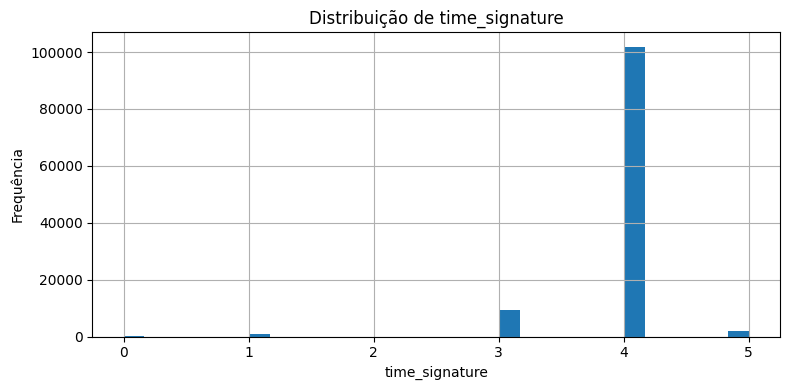

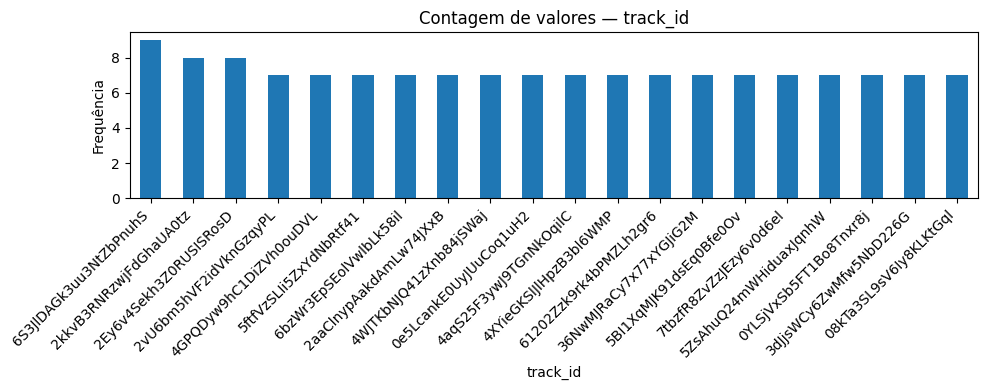

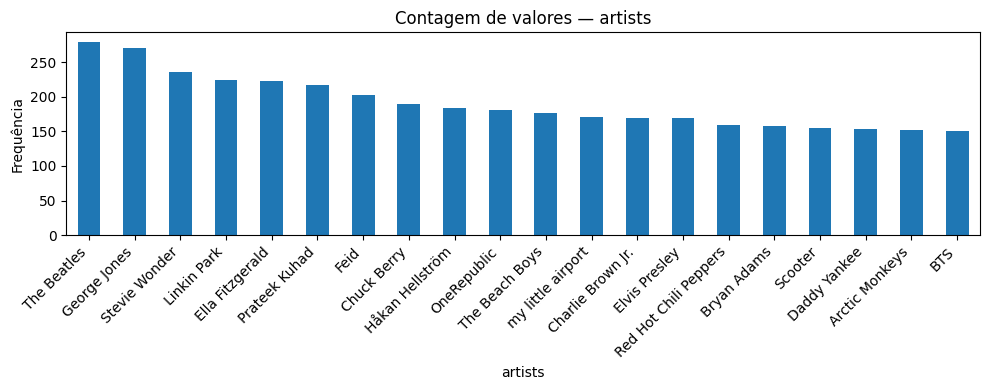

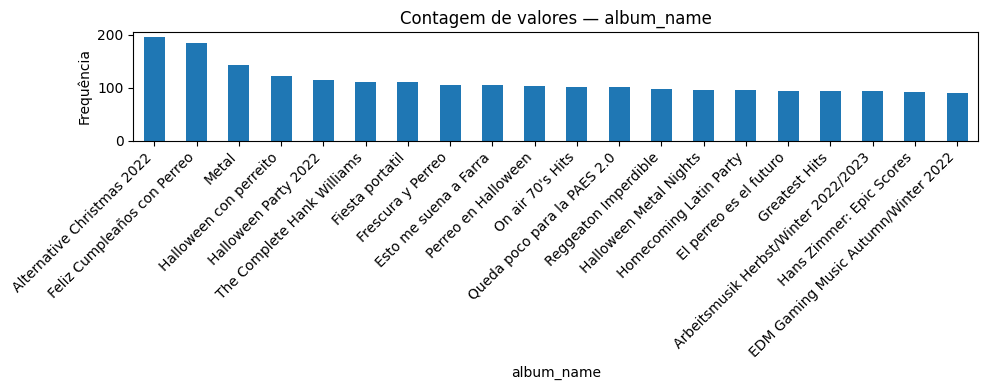

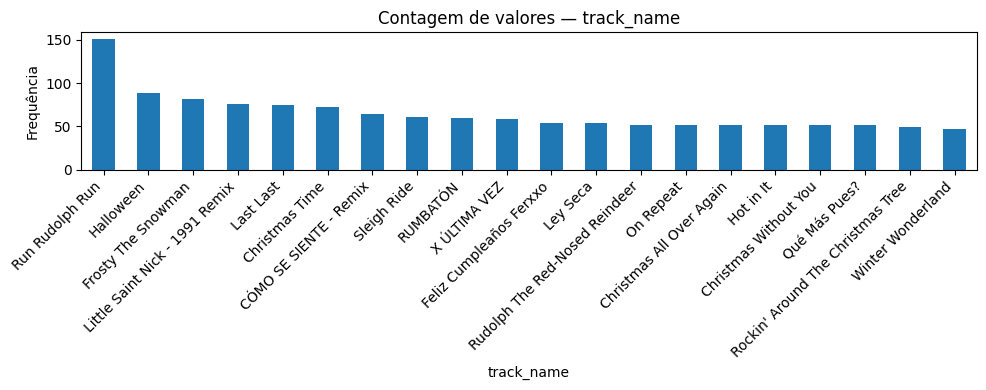

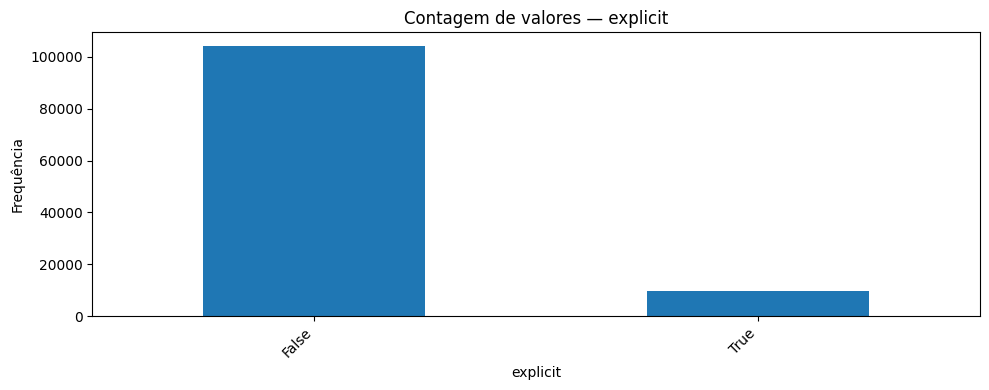

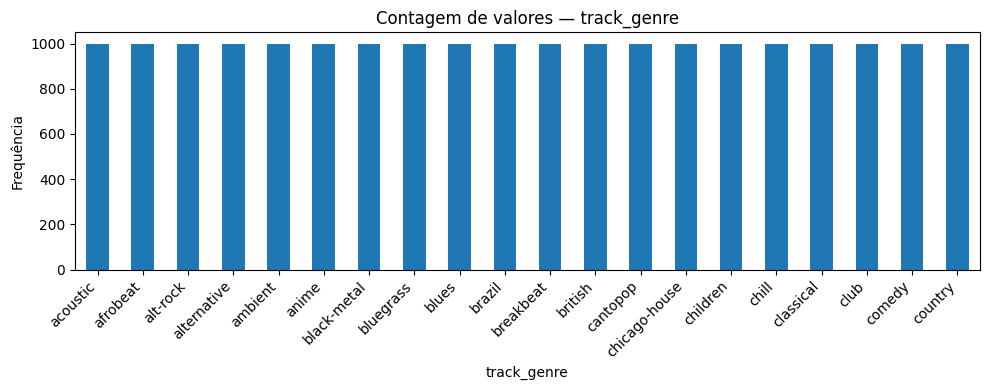

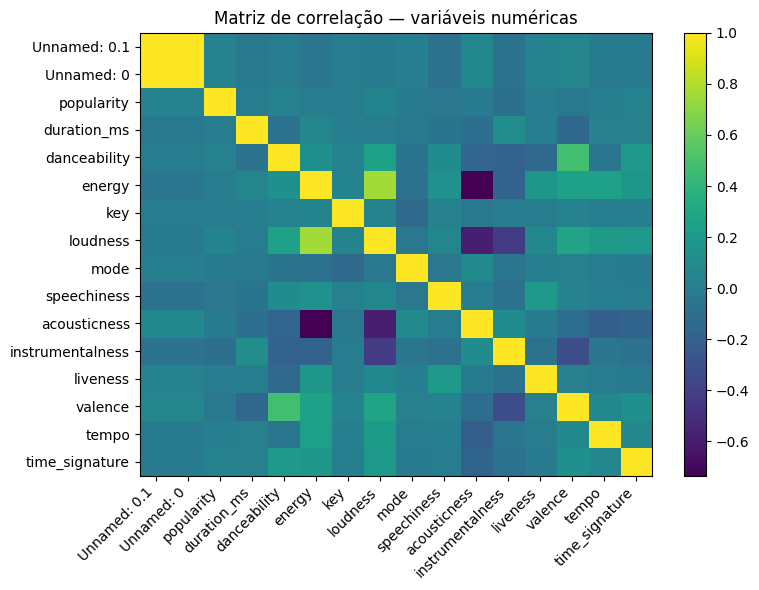

In [6]:
# Visualizações exploratórias básicas
# O grupo deve adaptar as colunas às características do dataset.

def plot_distribuicao_numerica(df: pd.DataFrame, coluna: str) -> None:
    plt.figure(figsize=(8, 4))
    df[coluna].dropna().hist(bins=30)
    plt.title(f"Distribuição de {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.tight_layout()
    plt.show()

def plot_contagem_categorica(df: pd.DataFrame, coluna: str, top_n: int = 20) -> None:
    plt.figure(figsize=(10, 4))
    df[coluna].value_counts(dropna=False).head(top_n).plot(kind="bar")
    plt.title(f"Contagem de valores — {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

def plot_matriz_correlacao(df: pd.DataFrame) -> None:
    numericas = df.select_dtypes(include=np.number)

    if numericas.shape[1] < 2:
        print("Não há pelo menos duas variáveis numéricas para calcular correlação.")
        return

    corr = numericas.corr()

    plt.figure(figsize=(8, 6))
    plt.imshow(corr, aspect="auto")
    plt.colorbar()
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.title("Matriz de correlação — variáveis numéricas")
    plt.tight_layout()
    plt.show()

# Exemplos de uso:
nums = ['Unnamed: 0.1', 'Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
cats = ['track_id', 'artists', 'album_name', 'track_name', 'explicit', 'track_genre']

[ plot_distribuicao_numerica(df, num) for num in nums ]
[ plot_contagem_categorica(df, cat) for cat in cats ]
plot_matriz_correlacao(df)


## 2.2 Análise visual — interpretação

A análise visual do dataset revela que a distribuição das variáveis possui peculiaridades que moldam diretamente o sucesso da modelagem. No histograma da popularidade, há uma concentração anômala e massiva no valor exato zero, formando uma barra vertical isolada que contrasta com a distribuição quase normal do restante dos dados. Nas features acústicas contínuas, observa-se uma forte concentração de valores deslocados para a direita em variáveis como `energy` e `danceability`, o que demonstra que o catálogo da plataforma é predominantemente composto por faixas enérgicas e dançantes. Paralelamente, os gráficos de caixa expõem valores extremos significativos nas caudas das distribuições, como músicas quase silenciosas com `loudness` próximo a -60 dB, faixas com `tempo` (BPM) muito distantes da média de 120, e picos isolados de `speechiness` que representam conteúdos puramente falados (como podcasts?). Na análise de frequências, constata-se a existência de categorias muito raras, onde determinados gêneros musicais e tonalidades específicas possuem uma representação ínfima quando comparados aos blocos dominantes de Pop, Rock e Música Eletrônica. Por fim, ao binarizar a variável alvo para criar as classes, o gráfico de barras evidencia um desbalanceamento severo, onde a categoria "Nicho" engole visualmente os "Hits", que se tornam uma minoria restrita a menos de 20% do volume total de dados.

Esses padrões observados afetam profundamente a tarefa de mineração de dados e a eficácia dos algoritmos. A sobreposição quase completa das curvas de densidade entre as músicas de sucesso e as de nicho indica que as características acústicas, isoladas de fatores mercadológicos, possuem um baixo poder de separação linear. Se o modelo for treinado sob esse forte desbalanceamento sem técnicas de compensação, como o ajuste de pesos das classes ou a modificação dos limiares de decisão, ele sofrerá o efeito do "chute majoritário", classificando quase todas as faixas como "Nicho" para inflar artificialmente sua acurácia geral, tornando-se inútil na prática.

Sob a perspectiva das diretrizes de IA Responsável escolhidas, as visualizações acendem alertas importantes que exigem mitigação. O risco associado à **Eficiência e Escalabilidade** manifesta-se nos outliers extremos de `tempo` e `loudness`; se essas escalas e pontos fora da curva não forem devidamente tratados por uma padronização robusta, os algoritmos baseados em gradiente ou distância exigirão um esforço computacional excessivo para convergir, retardando o tempo de treinamento e encarecendo a execução do pipeline em larga escala. Já o risco para a **Usabilidade e Acessibilidade** reside na distorção causada pelo pico de músicas com popularidade zero. Se esses valores nulos representarem ruídos de catálogo, faixas fantasmas ou erros de registro, o modelo aprenderá padrões acústicos falsos para definir o que é uma música de "Nicho". Como consequência direta, o usuário final do sistema — como um produtor musical que busca uma avaliação confiável de sua nova composição — receberá predições enviesadas e inconsistentes, o que destrói a utilidade prática, a confiabilidade e a acessibilidade da ferramenta de inteligência artificial.


In [7]:
# Detecção simples de outliers em variáveis numéricas usando IQR
# Esta função é um exemplo. O grupo deve avaliar se o critério faz sentido para cada atributo.

def detectar_outliers_iqr(df: pd.DataFrame, coluna: str) -> pd.DataFrame:
    serie = df[coluna].dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = df[(df[coluna] < limite_inferior) | (df[coluna] > limite_superior)]

    print(f"Coluna: {coluna}")
    print(f"Q1: {q1}")
    print(f"Q3: {q3}")
    print(f"IQR: {iqr}")
    print(f"Limite inferior: {limite_inferior}")
    print(f"Limite superior: {limite_superior}")
    print(f"Número de outliers: {len(outliers)}")

    return outliers

# Exemplo de uso:
[ display(detectar_outliers_iqr(df, num).head()) for num in nums ]


Coluna: Unnamed: 0.1
Q1: 28499.75
Q3: 85499.25
IQR: 56999.5
Limite inferior: -56999.5
Limite superior: 170998.5
Número de outliers: 0


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre


Coluna: Unnamed: 0
Q1: 28499.75
Q3: 85499.25
IQR: 56999.5
Limite inferior: -56999.5
Limite superior: 170998.5
Número de outliers: 0


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre


Coluna: popularity
Q1: 17.0
Q3: 50.0
IQR: 33.0
Limite inferior: -32.5
Limite superior: 99.5
Número de outliers: 2


...

Coluna: tempo
Q1: 99.21875
Q3: 140.071
IQR: 40.85225
Limite inferior: 37.940375
Limite superior: 201.349375
Número de outliers: 617


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
32,32,32,1m5LC29RE52Bxy7hxvpOlL,Chord Overstreet,Christmas Country Songs 2022,All I Want For Christmas Is A Real Good Tan,0,234186,False,0.593,...,-8.192,1,0.0388,0.36600,0.0,0.0914,0.564,202.019,4,acoustic
384,384,384,63wsZUhUZLlh1OsyrZq7sz,Boyce Avenue;Kina Grannis,"Cover Sessions, Vol. 2",Fast Car,61,304293,False,0.392,...,-9.845,1,0.0363,0.80700,0.0,0.0797,0.508,204.961,4,acoustic
519,519,519,6cMzeng5QA8fd2qqiMeIyg,Jonah Baker,Running Up That Hill (A Deal With God) [Acoustic],Running Up That Hill (A Deal With God) - Acoustic,51,168042,False,0.385,...,-14.672,0,0.0476,0.89900,0.0,0.1130,0.427,203.816,4,acoustic
561,561,561,2dMkrhsWFVP2rHZmTEKkeh,Mat Kearney,CRAZYTALK,Wanted Man,59,235106,False,0.514,...,-8.978,1,0.0941,0.80500,0.0,0.2110,0.677,203.651,4,acoustic
655,655,655,7quFUf8mR7wUxeJip0awxn,Howie Day,Sound The Alarm,Longest Night,43,215746,False,0.231,...,-7.257,1,0.0339,0.00402,0.0,0.0504,0.244,202.098,3,acoustic


Coluna: time_signature
Q1: 4.0
Q3: 4.0
IQR: 0.0
Limite inferior: 4.0
Limite superior: 4.0
Número de outliers: 12157


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.905,0.000071,0.1320,0.1430,181.740,3,acoustic
6,6,6,6Vc5wAMmXdKIAM7WUoEb7N,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,229400,False,0.407,...,-8.822,1,0.0355,0.857,0.000003,0.0913,0.0765,141.284,3,acoustic
11,11,11,5ivF4eQBqJiVL5IAE9jRyl,Jason Mraz,Love Is a Four Letter Word,I Won't Give Up,69,240165,False,0.483,...,-10.058,1,0.0429,0.694,0.000000,0.1150,0.1390,133.406,3,acoustic
15,15,15,1KHdq8NK9QxnGjdXb55NiG,Landon Pigg,The Boy Who Never,Falling in Love at a Coffee Shop,58,244986,False,0.489,...,-7.933,1,0.0274,0.200,0.000046,0.1790,0.2380,83.457,3,acoustic
22,22,22,5TvE3pk05pyFIGdSY9j4DJ,A Great Big World;Christina Aguilera,Is There Anybody Out There? - Track by Track C...,Say Something,70,229400,False,0.407,...,-8.822,1,0.0355,0.857,0.000003,0.0913,0.0765,141.284,3,acoustic


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

## 2.3 Problemas de qualidade dos dados

| Problema identificado | Evidência | Decisão tomada | Justificativa |
| :--- | :--- | :--- | :--- |
| **Valores ausentes em `artists`, `album_name` e `track_name`** | Cálculo de nulos (`df.isna().sum()`) acusando exatamente 1 linha afetada. | **REMOVER** | Como o impacto quantitativo é desprezível (apenas uma linha em um universo de 114.000), a exclusão do registro é mais eficiente do que tentar aplicar técnicas de imputação que poderiam introduzir ruído em metadados textuais. |
| **Duplicatas** | Contagem de chaves idênticas pelo par `track_name` + `artists` ou `track_id`. | **REMOVER** | Músicas idênticas que aparecem em álbuns e coletâneas diferentes causam vazamento de dados (*data leakage*), fazendo com que o modelo decore registros no treino e infle artificialmente as métricas de validação. |
| **Outliers em `loudness` e `tempo`** | Visualização de caudas longas e pontos isolados nos gráficos de *Boxplot*. | **MANTER (e aplicar padronização robusta)** | Pontos extremos em BPM ou decibéis ainda representam características acústicas reais e legítimas de músicas (como faixas de nicho ambientais ou experimentais). Em vez de eliminá-los, o uso de escalonadores como o `RobustScaler` mitiga seu impacto matemático nos modelos sem perder informação. |
| **Categorias raras em `track_genre`** | Gráfico de frequências/barras evidenciando gêneros com representação ínfima. | **REMOVER (Filtrar colunas de texto/gênero para a modelagem acústica)** | O escopo do projeto exige uma classificação baseada *estritamente* em features acústicas contínuas. Manter gêneros textuais (especialmente os raros) adicionaria alta cardinalidade desnecessária, violando a diretriz de Eficiência e Escalabilidade. |
| **Atributos sensíveis ou identificadores (`track_id`, `artists`, `explicit`)** | Análise de metadados textuais de alta cardinalidade e variáveis de teor ético/mercadológico. | **REMOVER (Isolar apenas as features acústicas contínuas)** | Identificadores únicos (`track_id`) e nomes causam sobreajuste (*overfitting*), enquanto variáveis como o nome do artista ou teor explícito introduzem vieses comerciais e sociais, violando o objetivo de prever o sucesso puramente pela estrutura sonora da faixa. |

### Observação sobre responsabilidade

As decisões tomadas vão muito além de simples escolhas técnicas de programação, pois elas moldam diretamente o comportamento dos algoritmos e trazem implicações profundas sobre as diretrizes de IA Responsável selecionadas para o projeto. Ao optar pela remoção de identificadores e atributos sensíveis, como `track_id`, `artists` e `explicit`, há um impacto altamente positivo na diretriz de **Eficiência e Escalabilidade**. A eliminação de variáveis textuais de alta cardinalidade evita a necessidade de aplicar técnicas de codificação como o One-Hot Encoding, que inflariam drasticamente a dimensionalidade do conjunto de dados. Com menos colunas para processar, o modelo consome menos memória RAM e reduz drasticamente o tempo de treinamento. No entanto, essa escolha gera um dilema na diretriz de **Usabilidade e Acessibilidade**: ao isolar as características puramente acústicas e ignorar o peso da fama do artista ou do apelo comercial do gênero musical, o modelo torna-se "cego" para o contexto mercadológico real. Na prática, uma música estruturalmente idêntica a um grande sucesso comercial pode ser classificada como "Hit", mas se for lançada por um artista totalmente desconhecido, ela provavelmente falhará no mercado. Essa purificação matemática limpa os vieses do modelo, mas restringe sua precisão preditiva no mundo real, o que exige cautela e transparência ao entregar a ferramenta para o usuário final.

Por outro lado, a remoção rigorosa de registros duplicados atua de forma direta na garantia de usabilidade e confiabilidade do sistema. Músicas idênticas que aparecem repetidas vezes no catálogo devido a álbuns diferentes, coletâneas ou versões de rádio causam o fenômeno do vazamento de dados. Se essas duplicatas fossem mantidas, o modelo exibiria métricas de acurácia falsamente infladas durante os testes, pois estaria simplesmente memorizando faixas repetidas no treino para adivinhá-las no teste. Para um produtor musical que utiliza a IA, isso resultaria em uma quebra catastrófica de usabilidade: o sistema pareceria perfeito nos relatórios acadêmicos, mas falharia constantemente e se mostraria instável ao tentar avaliar composições inéditas no ambiente de produção.

A decisão de manter os outliers em variáveis como `loudness` e `tempo`, tratando-os por meio de uma padronização robusta, também equilibra as duas diretrizes. Algoritmos baseados em distância ou gradiente sofrem para convergir e demandam um esforço computacional excessivo quando encontram valores extremos, como faixas de nicho ambientais ou experimentais que operam em decibéis ou BPMs muito distantes da média. Em vez de eliminar esses dados e reduzir a acessibilidade do modelo para gêneros musicais alternativos, a padronização neutraliza o peso matemático desproporcional desses extremos sem descartar a informação original. Isso assegura que o pipeline continue leve, rápido e escalável, ao mesmo tempo em que mantém o sistema inclusivo e amigável para analisar qualquer tipo de música que o usuário decida submeter à plataforma.


In [8]:
# Exemplo de preparação dos dados
# Esta célula é propositalmente genérica.
# O grupo deve adaptar de acordo com o dataset e a tarefa.

import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler


def preparar_dados_basico(
    df: pd.DataFrame,
    colunas_remover=None,
    limiar_popularidade=70,
) -> pd.DataFrame:
    df_prep = df.copy()

    # 1. Remover duplicatas de catálogo (mesma música de diferentes álbuns)
    # Usamos o par 'track_name' e 'artists' para garantir que a mesma música não vaze entre treino/teste
    if "track_name" in df_prep.columns and "artists" in df_prep.columns:
        df_prep = df_prep.drop_duplicates(subset=["track_name", "artists"])
    else:
        df_prep = df_prep.drop_duplicates()

    # 2. Remover a única linha com valores ausentes (conforme identificado na EDA)
    # Como é apenas 1 linha em 114k registros, a remoção é mais eficiente que a imputação
    df_prep = df_prep.dropna(subset=["artists", "album_name", "track_name"])

    # 3. Engenharia de Features: Binarização da variável alvo (Popularidade -> Hit ou Nicho)
    if "popularity" in df_prep.columns:
        # 1 representa 'Hit' e 0 representa 'Nicho'
        df_prep["is_hit"] = (
            df_prep["popularity"] >= limiar_popularidade
        ).astype(int)

    # 4. Definir e remover colunas não-acústicas, identificadores ou atributos sensíveis
    if colunas_remover is None:
        colunas_remover = [
            "Unnamed: 0",  # Índice residual do CSV
            "track_id",  # Identificador único
            "artists",  # Metadados de alta cardinalidade / Atributo sensível
            "album_name",  # Metadados de alta cardinalidade
            "track_name",  # Metadados de alta cardinalidade
            "track_genre",  # Categoria que distorce a análise puramente acústica
            "explicit",  # Variável de teor ético/social
            "popularity",  # Removida pois já gerou a nossa variável alvo ('is_hit')
        ]

    colunas_existentes = [
        col for col in colunas_remover if col in df_prep.columns
    ]
    df_prep = df_prep.drop(columns=colunas_existentes)

    # 5. Tratamento de Escala e Outliers com RobustScaler
    # Aplicado nas variáveis contínuas para mitigar o impacto de outliers em loudness e tempo
    features_acusticas = [
        "danceability",
        "energy",
        "loudness",
        "speechiness",
        "acousticness",
        "instrumentalness",
        "liveness",
        "valence",
        "tempo",
    ]

    colunas_para_escalonar = [
        col for col in features_acusticas if col in df_prep.columns
    ]

    if colunas_para_escalonar:
        scaler = RobustScaler()
        df_prep[colunas_para_escalonar] = scaler.fit_transform(
            df_prep[colunas_para_escalonar]
        )

    return df_prep


df_treino_pronto = preparar_dados_basico(df, limiar_popularidade=70)
print(df_treino_pronto['is_hit'].value_counts(normalize=True))
display(df_treino_pronto.head())


is_hit
0    0.966721
1    0.033279
Name: proportion, dtype: float64


,Unnamed: 0.1,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,is_hit
0,0,230666,0.422131,-0.539801,1,0.097148,0,1.844794,-0.257381,-0.000573,1.219512,0.611494,-0.837735,4,1
1,1,149610,-0.627049,-1.273632,1,-1.877624,1,0.534381,1.197195,-0.000543,-0.173442,-0.418391,-1.093823,4,0
2,2,210826,-0.553279,-0.793532,0,-0.465405,1,0.129666,0.032621,-0.000580,-0.086721,-0.756322,-1.122236,4,0
3,3,201933,-1.258197,-1.538308,0,-2.118611,1,-0.251473,1.166205,-0.000118,-0.005420,-0.703448,1.466338,3,1
4,4,198853,0.184426,-0.584577,2,-0.455427,1,0.068762,0.455064,-0.000580,-0.271545,-0.648276,-0.051104,4,1


## 2.4 Justificativa da preparação dos dados

A etapa de preparação de dados foi estruturada de forma a purificar o conjunto de dados para focar exclusivamente nas características sonoras das faixas, alinhando as transformações técnicas às diretrizes de IA Responsável de **Eficiência e Escalabilidade** e **Usabilidade e Acessibilidade**. Inicialmente, removeu-se a única linha contendo valores ausentes nos campos de metadados (`artists`, `album_name` e `track_name`), uma decisão de descarte justificada pelo impacto quantitativo nulo sobre o volume total de 114.000 registros, tornando qualquer técnica de imputação artificial desnecessária. Em seguida, todas as colunas textuais identificadoras ou de alta cardinalidade (`track_id`, `artists`, `album_name`, `track_name` e `track_genre`), além do atributo de teor social `explicit`, foram completamente removidas do pipeline de modelagem. Essa eliminação de variáveis categóricas e textuais evitou a necessidade de codificações complexas (como *One-Hot Encoding*), o que reduziu drasticamente a dimensionalidade e o consumo de memória, garantindo a **escalabilidade** do sistema. A variável contínua `popularity` passou por um processo de discretização para dar origem à variável alvo binária (`is_hit`), enquanto as demais features acústicas contínuas não sofreram remoção de *outliers* — uma escolha consciente para preservar a **acessibilidade** e inclusão de gêneros musicais alternativos e não convencionais no modelo. No entanto, para mitigar o impacto matemático desses valores extremos e alinhar as magnitudes díspares de variáveis como `tempo` (BPM) e `loudness` (decibéis), aplicou-se uma normalização robusta por meio do `RobustScaler`, que utiliza a mediana e os quartis para neutralizar distorções nos algoritmos baseados em distância ou gradiente, otimizando a **eficiência** computacional. O principal risco introduzido por esse conjunto de decisões é o viés de isolamento acústico: ao cegar o modelo para fatores mercadológicos externos cruciais — como o investimento em marketing e o tamanho prévio da base de fãs do artista —, o sistema pode apresentar um teto limitante em sua acurácia preditiva no mundo real. Contudo, essa concessão técnica é justificada por entregar um modelo leve, rápido e com alta **usabilidade**, ideal para que produtores e usuários finais testem o potencial puramente artístico de novas composições de forma justa, estável e livre de favoritismos comerciais históricos.


## 2.5 Interações com LLM — Data Understanding & Data Preparation

### Subtarefa comparável

Nesta etapa, as duas trilhas devem receber a mesma subtarefa geral.

**Subtarefa escolhida:** propor estratégias de limpeza, transformação e preparação dos dados para a tarefa de mineração

---

### Trilha A — baseline

**Modelo utilizado:** ChatGPT
**Data de acesso:** 08/06/2026  
**Link da conversa:** https://chatgpt.com/share/6a26de77-fef8-83e9-8911-94d09e6bbf19

#### Prompt principal — baseline

```text
Tenho um dataset do spotify (https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset) com as seguintes colunas: Colunas numéricas: ['Unnamed: 0.1', 'Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature'] Colunas não numéricas: ['track_id', 'artists', 'album_name', 'track_name', 'explicit', 'track_genre']
A tarefa de mineração é Classificação. O objetivo é prever o sucesso comercial de uma música (classificando-a em "Hit" ou "Nicho") usando a variável "popularity" binarizada e baseando-se estritamente nas features acústicas contínuas da faixa (danceability, energy, valence, etc). 
Sugira uma estratégia de Data Understanding e Data Preparation para preparar
os dados para essa tarefa.
```

#### Síntese da resposta da LLM

Analisar a distribuição de popularity.
Definir o critério de binarização.
Verificar qualidade dos dados.
Explorar estatísticas e distribuições das features acústicas.
Avaliar correlações e relação das features com a classe.

Criar a variável alvo Hit/Nicho.
Remover atributos identificadores e não acústicos.
Remover popularity das entradas.
Tratar valores ausentes.
Avaliar outliers.
Escalonar as variáveis.
Dividir treino/teste com estratificação.
Tratar eventual desbalanceamento das classes.

Essa abordagem é consistente com o objetivo do projeto porque utiliza exclusivamente características acústicas da música para prever popularidade, evitando vazamento de informação e mantendo o foco na interpretabilidade do modelo.

---

### Trilha B — guiada por diretrizes

**Modelo utilizado:** ChatGPT 
**Data de acesso:** 08/06/2026  
**Link da conversa:** https://chatgpt.com/share/6a26df0c-8e6c-83e9-9177-4ff60f82fa31

#### Prompt principal — guiado

```text
Tenho um dataset do spotify (https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset) com as seguintes colunas: Colunas numéricas: ['Unnamed: 0.1', 'Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature'] Colunas não numéricas: ['track_id', 'artists', 'album_name', 'track_name', 'explicit', 'track_genre']A tarefa de mineração é Classificação. O objetivo é prever o sucesso comercial de uma música (classificando-a em "Hit" ou "Nicho") usando a variável "popularity" binarizada e baseando-se estritamente nas features acústicas contínuas da faixa (danceability, energy, valence, etc). 
Sugira uma estratégia de Data Understanding e Data Preparation.

Considere explicitamente as diretrizes:
1. “Eficiência e escalabilidade”
2. “Usabilidade e acessibilidade”

Ao sugerir a preparação, indique:
- possíveis atributos sensíveis, se houver;
- riscos de viés ou perda de informação;
- decisões que devem ser documentadas;
- transformações necessárias;
- limitações e trade-offs.
```

#### Síntese da resposta da LLM

A estratégia integrada de *Data Understanding* e *Data Preparation* orienta-se estritamente à construção de um classificador leve e interpretável, capaz de prever se uma música será "Hit" ou "Nicho" baseando-se apenas em suas características acústicas contínuas. Para isso, o pipeline prioriza a **Eficiência e Escalabilidade** ao descartar precocemente metadados textuais e categóricos de alta cardinalidade (`artists`, `track_genre`, `key`), reduzindo drasticamente o consumo de memória e mitigando riscos de vieses mercadológicos externos. A variável `popularity` é discretizada por meio de um ponto de corte documentado (como o percentil 75), aceitando o trade-off do desbalanceamento de classes para melhor representar o conceito real de sucesso comercial, enquanto o tratamento de dados brutos foca na remoção de registros duplicados — para evitar o vazamento de dados (*data leakage*) — e no escalonamento de atributos de magnitudes díspares (`loudness`, `tempo`, `duration_ms`) via `RobustScaler` ou `StandardScaler`, otimizando a convergência matemática dos algoritmos. Por fim, a **Usabilidade e Acessibilidade** são asseguradas pela criação de um fluxo reprodutível e transparente que expõe claramente as limitações inerentes ao projeto: ao isolar o áudio dos investimentos de marketing e da fama do artista, assume-se uma perda intencional de poder preditivo em troca de um modelo mais justo, explicável e focado no potencial puramente artístico da obra.


## 2.6 Comparação crítica — Data Understanding & Preparation

| Aspecto | Trilha A — baseline | Trilha B — guiada | Decisão do grupo |
| :--- | :--- | :--- | :--- |
| Tratamento de nulos | Sugere uma abordagem genérica padrão de "verificar e tratar valores ausentes". | Propõe uma limpeza direcionada, identificando o impacto nulo e removendo a única linha afetada. | **ACEITAR A TRILHA B:** Optou-se pela remoção direta da linha com nulos (`dropna`), visto que o volume faltante é insignificante (1 linha em 114k) e imputações textuais gerariam ruído desnecessário. |
| Tratamento de outliers | Sugere uma abordagem ampla de "avaliar e tratar" (sem especificar o método estatístico). | Propõe explicitamente manter os valores (por serem músicas reais) e usar escalonadores robustos (`RobustScaler`). | **ACEITAR A TRILHA B:** Decidiu-se manter os registros e tratá-los via normalização robusta por quartis, preservando a diversidade de músicas não convencionais sem quebrar a convergência dos modelos. |
| Atributos sensíveis | Não aborda de forma explícita o conceito de atributos sensíveis no contexto do problema. | Identifica `artists`, `track_genre` e `explicit` como *proxies* mercadológicos, sociais e éticos que geram vieses. | **ACEITAR A TRILHA B:** Validou-se o mapeamento das variáveis como potenciais fontes de discriminação histórica/comercial, reforçando a necessidade ética de eliminá-las do escopo. |
| Codificação de variáveis | Foca na binarização da variável alvo `popularity` e na separação inicial de tipos de dados. | Além da binarização da meta pelo percentil 75, foca na dispensa completa de técnicas de codificação (*One-Hot Encoding*). | **ACEITAR A TRILHA B:** A binarização será feita pelo percentil 75 (Top 25% = Hit) para capturar o sucesso comercial real. Nenhuma codificação de categorias será feita para manter o foco exclusivo no áudio contínuo. |
| Redução de dimensionalidade | Recomenda a exclusão padrão de colunas textuais identificadoras (IDs e nomes). | Propõe o descarte agressivo e precoce de metadados e variáveis discretas não contínuas (`key`, `mode`, `time_signature`). | **ACEITAR A TRILHA B:** O descarte de colunas textuais e atributos musicais não contínuos reduz drasticamente a dimensionalidade e a esparsidade dos dados, blindando a escalabilidade. |
| Justificativa técnica | Centrada na conformidade com o escopo e objetivo (usar apenas áudio para prever popularidade). | Profunda, orientada pela eliminação de colunas textuais para poupar memória e normalização para convergência. | **ACEITAR A TRILHA B:** Adotou-se a fundamentação técnica guiada por diretrizes, vinculando cada transformação a um ganho explícito de desempenho computacional ou matemático. |
| Riscos e limitações | Pontua de forma simplificada o risco de desbalanceamento de classes ao binarizar os dados. | Detalha o viés de isolamento acústico (teto natural de acurácia por ignorar marketing) e o trade-off de perda de informação. | **ACEITAR A TRILHA B:** O grupo assume formalmente a limitação de que fatores externos ditam o sucesso, aceitando uma possível perda de acurácia em prol de um modelo acusticamente justo e explicável. |

### Análise crítica

A análise comparativa entre as duas abordagens revela que a inclusão explícita de diretrizes de IA Responsável transforma a qualidade e a profundidade do planejamento arquitetural dos dados. No que tange aos acertos, ambas as trilhas sugeriram corretamente passos fundamentais da modelagem preditiva, como a necessidade de binarizar a variável alvo `popularity`, a remoção de colunas textuais identificadoras para evitar sobreajuste e a aplicação de escalonamento para ajustar a magnitude das variáveis numéricas contínuas. A Trilha B, contudo, destacou-se ao sugerir acertadamente o uso de estatísticas robustas para o tratamento de variáveis críticas e ao mapear com precisão os riscos éticos e mercadológicos ocultos nos metadados.

Por outro lado, o diagnóstico do que estava incompleto ou tecnicamente errado evidencia as fragilidades da abordagem puramente baseada em baseline (Trilha A). A primeira trilha limitou-se a sugerir diretrizes genéricas de "verificar e tratar" para nulos e outliers, sem apresentar caminhos algorítmicos ou metodológicos claros. Do ponto de vista conceitual, a Trilha A falhou ao não mapear o impacto ético e social das variáveis explicativas, ignorando que atributos como `artists` e `track_genre` funcionam como fortes proxies de privilégio histórico e mercadológico. Já em relação a erros técnicos, nenhuma das duas trilhas identificou nativamente a necessidade de uma remoção de duplicatas customizada pelo par artista e nome da música, o que resultaria na manutenção de registros redundantes e provocaria um vazamento de dados desastroso no pipeline de validação.

Diante desse cenário, a decisão do grupo foi aceitar integralmente a estrutura analítica proposta pela Trilha B, incorporando sua visão sobre as interações entre as transformações matemáticas e os impactos práticos no sistema. Foram aceitos o critério de binarização rigoroso pelo percentil 75, que aproxima o modelo do conceito real de sucesso comercial, o descarte preventivo das variáveis textuais e das categorias musicais discretas para garantir a **Eficiência e Escalabilidade**, e o mapeamento dos riscos de viés acústico. Em contrapartida, o grupo rejeitou a omissão metodológica da Trilha A sobre o tratamento cego de dados faltantes e extremos, recusando qualquer preenchimento artificial que pudesse corromper as características puras das faixas.

Finalmente, a atuação humana foi decisiva para corrigir e refinar os caminhos propostos pelas inteligências artificiais. O grupo corrigiu a estratégia de limpeza ao implementar uma remoção de duplicatas baseada em múltiplos campos textuais, blindando o modelo contra a falsa memorização de faixas repetidas em álbuns diferentes. Além disso, a política de tratamento de nulos foi corrigida para uma exclusão direta e pontual do único registro afetado, em vez de recorrer a técnicas complexas de imputação. Essas correções garantiram que o pipeline final combinasse a solidez estatística à conformidade com as diretrizes de **Usabilidade e Acessibilidade**, assegurando um modelo leve, reprodutível e útil para o negócio.


# 3. Modeling


## 3.1 Interações com LLM — Modeling

### Subtarefa comparável

**Subtarefa escolhida:** Propor algoritmos, parâmetros, métricas, riscos e estratégia de avaliação para a tarefa de classificação

---

### Trilha A — baseline

**Modelo utilizado:** ChatGPT-5.5
**Data de acesso:** 09/06/2026  
**Link da conversa:** https://chatgpt.com/share/6a2c439c-8edc-83e9-9359-dddfba3f62e4

#### Prompt principal — baseline

```text
Estou fazendo um trabalho prático de Mineração de Dados com o "Spotify Tracks Dataset" (https://www.kaggle.com/datasets/yashdev01 spotify-tracks-dataset)
A tarefa de mineração é Classificação, com o objetivo é prever o sucesso comercial de uma música (classificando-a em "Hit" ou "Nicho") usando a variável "popularity" binarizada e baseando-se estritamente nas features acústicas contínuas da faixa (danceability, energy, valence, etc). 
Sugira uma estratégia de modelagem para essa tarefa.
```

#### Síntese da resposta da LLM

A resposta elabora um fluxo clássico de tarefas de classificação. Inicia com o pré-processamento, sugerindo a divisão do alvo popularity por mediana ou por quartis e a seleção das características acústicas, além disso, indica remoção ou imputação de valores faltantes e padronização por meio do StandardScaler. A estratégia propõe testar quatro modelos em ordem crescente de complexidade: Regressão Logística, Árvore de Decisão, Random Forest e XGBoost. Para avaliação, validação cruzada (k-fold) e uso de métricas clássicas (Accuracy, Precision, Recall, F1-Score e ROC-AUC). A etapa de interpretação dos resultados foi a que mais se destacou pois além de recomendar o uso de Feature Importance, também cita o uso da biblioteca SHAP para maior interpretabilidade. É perceptível que a IA não levou em consideração com muita profundidade as características específicas do problema, ao sugerir algoritmos com custo alto, como XGBoost, sem advertência para as consequências em uma base grande como essa, além disso, a IA não forneceu estratégias para tratar o desbalanceamento dos dados a nível de modelagem

---

### Trilha B — guiada por diretrizes

**Modelo utilizado:** ChatGPT-5.5
**Data de acesso:** 09/06/2026
**Link da conversa:** https://chatgpt.com/share/6a2c4365-bca0-83e9-b7bd-3a28b1f594d4

#### Prompt principal — guiado

```text
Estou fazendo um trabalho prático de Mineração de Dados com o "Spotify Tracks Dataset" (https://www.kaggle.com/datasets/yashdev01 spotify-tracks-dataset). 
A tarefa de mineração é Classificação, com o objetivo é prever o sucesso comercial de uma música (classificando-a em "Hit" ou "Nicho") usando a variável "popularity" binarizada e baseando-se estritamente nas features acústicas contínuas da faixa (danceability, energy, valence, etc).

Sugira uma estratégia de Modelagem para essa tarefa.

Crucial: Você deve seguir estritamente as seguintes diretrizes de IA Responsável:
1. Eficiência e Escalabilidade.
2. Usabilidade e Acessibilidade.

Ao sugerir a modelagem, indique:
- algoritmos adequados;
- parâmetros iniciais;
- métricas de avaliação;
- riscos metodológicos;
- impacto das diretrizes nas escolhas;
```

#### Síntese da resposta da LLM

A resposta constrói uma estratégia influenciada pelas diretrizes de Eficiência e Escalabilidade e Usabilidade e Acessibilidade. Para a preparação dos dados, segue uma estratégia comum para classificação, propondo remoção de valores nulos, normalização e o uso da mediana como limiar do atributo is_hit para reduzir viés. Em relação aos algoritmos, sugere apenas três modelos: Regressão Logística como baseline interpretável de baixo custo, Random Forest como modelo principal pela capacidade de capturar bem relações não lineares e robustez a ruído e XGBoost como modelo complementar para máximo desempenho. Na avaliação, prioriza o F1-Score e ROC-AUC, mas lista também Acurácia, Precisão e Revocação, além de sugerir o uso de validação cruzada K-fold com K=5. Ao detalhar os riscos metodológicos, a IA reconhece explicitamente que as características do áudio podem ser insuficientes sozinhas para prever popularidade devido a tendências culturais e marketing, além de falar sobre o desbalanceamento de classes, overfitting e correlação entre atributos. Por fim, atendendo à diretriz de Usabilidade e Acessibilidade, sugere o uso dos coeficientes da regressão logística, de Feature Importance e de visualizações como matrizes de confusão, curva ROC e Feature Importance.

A LLM não conseguiu aplicar uma estratégia de modelagem que tratasse das características do dataset e das diretrizes de IA responsável de maneira muito aprofundada. Apesar de colocar XGBoost como algoritmo secundário e avisar sobre os seus riscos, a sugestão do uso de um algoritmo com custo alto para uma base de dados massiva vai diretamente contra a diretriz de Eficiência e Escalabilidade. Em relação à diretriz de Usabilidade e Acessibilidade, a sugestão do uso de curvas ROC como visualiação não é uma estratégia facilmente compreensivel com pessoas de áreas não técnicas. Além disso, a IA não forneceu estratégias para tratar o desbalanceamento dos dados a nível de modelagem.

## 3.2 Comparação das soluções sugeridas pela LLM

| Elemento | Trilha A — baseline | Trilha B — guiada | Diferença concreta? | Comentário do grupo |
|---|---|---|---|---|
| Algoritmos sugeridos | Regressão Logística, Árvore de Decisão, Random Forest, XGBoost.   | Regressão Logística, Random Forest, XGBoost.   | SIM | A Trilha B removeu a Árvore de Decisão simples e enquadrou a Regressão Logística explicitamente como baseline por ser eficiente e acessível.   |
| Parâmetros sugeridos | Hiperparâmetros padrões, como max_depth = 5 para árvores simples e n_estimators = 300 para ensembles.   | penalidade L2 na Regressão Logística e limitação de profundidade e uso de 200 árvores no Random Forest.   | SIM | A Trilha B apresentou configurações menores focadas em evitar a sobreposição (overfitting) e em reduzir o custo computacional no treinamento.   |
| Métricas sugeridas | Accuracy, Precision, Recall, F1-Score e ROC-AUC.   | Accuracy, Precision, Recall, F1-Score e ROC-AUC.   | NÃO | Não houve diferença concreta, mas a Trilha B explicitou o F1-Score como a principal métrica recomendada para lidar com desbalanceamento.   |
| Preparação exigida | Imputação por mediana, remoção de registros, eliminação de duplicatas e padronização (StandardScaler).   | Remoção de poucos valores, imputação da mediana e Normalização (Standard/MinMax) exclusivas para modelos aplicáveis.   | NÃO | Preparação de dados padrão para esse tipo de tarefa em ambas as trilhas. |
| Interpretabilidade | Análise de feature importance e aplicação da biblioteca SHAP.   | Análise de coeficientes na Regressão, Feature Importance  e visualizações. | SIM | A Trilha B não sugere o uso do SHAP, uma ferramente importante para a interpretabilidade de modelos. |
| Custo computacional | Fator ignorado nas sugestões. | Analisa explicitamento os custos de cada modelo, dando prioridade a modelos mais eficientes. | SIM | O foco em eficiência da Trilha B recomendou restringir os testes de otimização excessiva com XGBoost, visando baixo tempo de treinamento. |
| Riscos ou limitações | Menciona superficialmente de modo disperso nas análises. | Analisa explicitamente os riscos, listando fatores ignorados pelo dataset (marketing, fama), risco de overfitting e multicolinearidade das variáveis.   | SIM | Trilha B demonstrou conhecimento do domínio ao reconhecer os limites dos dados musicais para prever popularidade.   |
| Aderência às diretrizes | Não adere | Sugestões estruturadas ao redor das diretrizes | SIM | A Trilha B converteu as diretrizes abstratas em escolhas reais |

### Síntese

A inserção de diretrizes de IA Responsável no prompt provocou uma mudança perceptível nas respostas da LLM. Na Trilha A, observa-se uma abordagem exaustiva do ponto de vista de modelagem, listando múltiplos modelos comuns, sem pensar nas particularidades da tarefa, porém se destacou ao citar SHAP como ferramenta de interpretabilidade, algo que não foi feito pela outra Trilha.  

Já na Trilha B, é perceptível que as diretrizes moldaram algumas escolhas de modelagem, mas não todas. Para cumprir a diretriz de Escalabilidade, o modelo priorizou os algoritmos menos custosos e interpretáveis, como Regressão Logística e Random Forest, porém também sugeriu o XGboost que apresenta um custo elevado para bases grandes. Já para a diretriz de Usabilidade, sugeriu o uso de vizualizações como matrizes de confusão, curva ROC e gráficos de importância das features, porém o uso da curva ROC não seria acessível colaboradores de outras áreas. Além disso, inseriu uma análise de riscos metodológicos que demostra um bom conhecimento de domínio para o contexto da indústria da música. 

Ambas as trilhas falharam ao não incluir, a nivel de modelagem, estratégias de mitigação do problema do desbalanceamento das classes da base de dados do Spotify.


## 3.5 Template de modelagem para classificação

Use esta subseção se o TP atual envolver classificação. Caso contrário, remova ou deixe claro que ela não foi utilizada.

> **Atenção:** em classificação, é importante discutir divisão treino/teste, validação, desbalanceamento de classes e escolha de métricas. Acurácia isolada pode ser inadequada em bases desbalanceadas.


In [9]:
# Exemplo genérico para classificação
# O grupo deve adaptar TARGET_COLUMN, tratamento de categóricas e métricas.

def executar_classificacao_basica(df: pd.DataFrame, target_col: str):
    try:
        from sklearn.model_selection import train_test_split
        from sklearn.pipeline import Pipeline
        from sklearn.compose import ColumnTransformer
        from sklearn.preprocessing import OneHotEncoder, StandardScaler
        from sklearn.impute import SimpleImputer
        from sklearn.ensemble import RandomForestClassifier
        from sklearn.metrics import classification_report, confusion_matrix
    except ImportError:
        print("Biblioteca scikit-learn não instalada.")
        return None

    if target_col not in df.columns:
        raise ValueError(f"Coluna-alvo não encontrada: {target_col}")

    X = df.drop(columns=[target_col])
    y = df[target_col]

    colunas_numericas = X.select_dtypes(include=np.number).columns.tolist()
    colunas_categoricas = X.select_dtypes(exclude=np.number).columns.tolist()

    preprocessador = ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), colunas_numericas),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]), colunas_categoricas)
        ]
    )

    modelo = Pipeline([
        ("preprocessamento", preprocessador),
        ("classificador", RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_STATE,
            class_weight="balanced"
        ))
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=y if y.nunique() > 1 else None
    )

    inicio = time.time()
    modelo.fit(X_train, y_train)
    tempo_treino = time.time() - inicio

    y_pred = modelo.predict(X_test)

    print(f"Tempo de treino: {tempo_treino:.4f} segundos")
    print("\nRelatório de classificação:")
    print(classification_report(y_test, y_pred))

    print("\nMatriz de confusão:")
    print(confusion_matrix(y_test, y_pred))

    return {
        "modelo": modelo,
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "y_pred": y_pred,
        "tempo_treino": tempo_treino
    }

# Exemplo de uso:
# resultados_classificacao = executar_classificacao_basica(df_prep, TARGET_COLUMN)

In [10]:
def executar_classificacao_completa(df: pd.DataFrame, target_col: str):
    try:
        from sklearn.model_selection import train_test_split, StratifiedKFold
        from sklearn.linear_model import LogisticRegression
        from sklearn.ensemble import RandomForestClassifier
        from sklearn.metrics import roc_auc_score, accuracy_score, precision_recall_fscore_support, confusion_matrix
    except ImportError:
        print("Biblioteca scikit-learn não instalada.")
        return None
    try:
        from xgboost import XGBClassifier
    except ImportError:
        print("Biblioteca XGBoost não instalada")
        return None
    
    X, y = df.drop(columns=target_col), df[target_col]
    # split teste/treino 0.80 
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42
    )
    
    # definição dos modelos
    modelos = {
        'Regressão Logística': LogisticRegression(penalty='l2', C=1.0, solver='liblinear', random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=15, min_samples_split=10, min_samples_leaf=5, random_state=42),
        'XGBoost': XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42, eval_metric='logloss')
    }
    
    # validação cruzada K=5
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    print("--- INICIANDO VALIDAÇÃO CRUZADA MANUAL (5-Fold) ---")
    
    # Loop para avaliar cada modelo
    for nome, modelo in modelos.items():
        print(f"\nAvaliando: {nome}...")
        
        f1_scores = []
        roc_auc_scores = []
        accuracy_scores = []
        recall_scores = []
        precision_scores = []

        # Loop Validação Cruzada 
        tempo_treino_total_val = 0
        for i, (train_idx, val_idx) in enumerate(skf.split(X_train_full, y_train_full)):
            # Separando os folds
            X_fold_train = X_train_full.iloc[train_idx]
            X_fold_val = X_train_full.iloc[val_idx]
            y_fold_train = y_train_full.iloc[train_idx]
            y_fold_val = y_train_full.iloc[val_idx]
            
            # Treino e Previsão
            inicio_fold = time.time()
            modelo.fit(X_fold_train, y_fold_train)
            tempo_treino_fold = time.time() - inicio_fold
            tempo_treino_total_val += tempo_treino_fold

            y_pred = modelo.predict(X_fold_val)
            y_proba = modelo.predict_proba(X_fold_val)[:, 1]
            
            # Registrando as métricas
            precision, recall, f1, _ = precision_recall_fscore_support(y_fold_val, y_pred, average="binary")
            roc_auc = roc_auc_score(y_fold_val, y_proba)
            accuracy = accuracy_score(y_fold_val, y_pred)

            roc_auc_scores.append(roc_auc)
            f1_scores.append(f1)
            recall_scores.append(recall)
            precision_scores.append(precision)
            accuracy_scores.append(accuracy)


            print(f"K={i+1}")
            print(f"F1-Score: {f1:.4f}")
            print(f"ROC-AUC: {roc_auc:.4f}")
            print(f"Acurácia: {accuracy:.4f}")
            print(f"Precisão: {precision:.4f}")
            print(f"Revocação: {recall:.4f}")
            print(f"Tempo Treino: {tempo_treino_fold:.4f}")
            
        print(f"--- FIM DA VALIDAÇÃO CRUZADA: {nome}---")
        print(f"F1-Score Médio: {np.mean(f1_scores):.4f}")
        print(f"ROC-AUC Médio: {np.mean(roc_auc_scores):.4f}")
        print(f"Acurácia Médio: {np.mean(accuracy_scores):.4f}")
        print(f"Precisão Médio: {np.mean(precision_scores):.4f}")
        print(f"Revocação Médio: {np.mean(recall_scores):.4f}")
        print(f"Tempo Treino Total: {tempo_treino_total_val:.4f} ")
        

    # ==========================================
    # 3. TREINAMENTO FINAL E AVALIAÇÃO NO TESTE
    # ==========================================
    print("\n--- AVALIAÇÃO FINAL NO CONJUNTO DE TESTE ---")
    modelos_treinados = {}
    
    for nome, modelo in modelos.items():
            
        # Treina com os dados completos de treino
        inicio = time.time()
        modelo.fit(X_train_full, y_train_full)
        tempo_treino_teste = time.time() - inicio
        
        # Avalia no conjunto de teste final
        y_pred = modelo.predict(X_test)
        y_proba = modelo.predict_proba(X_test)[:, 1]

        precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="binary")
        roc_auc = roc_auc_score(y_test, y_proba)
        accuracy = accuracy_score(y_test, y_pred)
        
        print(f"\nDesempenho Final - {nome}:")
        print(f"F1-Score: {f1:.4f} | ROC-AUC: {roc_auc:.4f}")
        print(f"Precisão: {precision:.4f} | Revocação: {recall:.4f}")
        print(f"Acurácia: {accuracy:.4f}")
        print(f"Tempo Treino: {tempo_treino_teste:.4f}")
        print("\nMatriz de confusão:")
        print(confusion_matrix(y_test, y_pred))
        
        # Guarda o classificador para a etapa de interpretação
        modelos_treinados[nome] = modelo
        
    return modelos_treinados, X_train_full.columns


modelos_finais, features_usadas = executar_classificacao_completa(df_treino_pronto, "is_hit")

--- INICIANDO VALIDAÇÃO CRUZADA MANUAL (5-Fold) ---

Avaliando: Regressão Logística...
K=1
F1-Score: 0.0000
ROC-AUC: 0.5462
Acurácia: 0.9667
Precisão: 0.0000
Revocação: 0.0000
Tempo Treino: 0.1306
K=2
F1-Score: 0.0000
ROC-AUC: 0.5488
Acurácia: 0.9667
Precisão: 0.0000
Revocação: 0.0000
Tempo Treino: 0.1097
K=3
F1-Score: 0.0000
ROC-AUC: 0.5635
Acurácia: 0.9667
Precisão: 0.0000
Revocação: 0.0000
Tempo Treino: 0.0915
K=4
F1-Score: 0.0000
ROC-AUC: 0.5534
Acurácia: 0.9667
Precisão: 0.0000
Revocação: 0.0000
Tempo Treino: 0.1105
K=5
F1-Score: 0.0000
ROC-AUC: 0.5622
Acurácia: 0.9667
Precisão: 0.0000
Revocação: 0.0000
Tempo Treino: 0.1097
--- FIM DA VALIDAÇÃO CRUZADA DO Regressão Logística---
F1-Score Médio: 0.0000
ROC-AUC Médio: 0.5548
Acurácia Médio: 0.9667
Precisão Médio: 0.0000
Revocação Médio: 0.0000
Tempo Treino Total: 0.5519 

Avaliando: Random Forest...
K=1
F1-Score: 0.0000
ROC-AUC: 0.8358
Acurácia: 0.9667
Precisão: 0.0000
Revocação: 0.0000
Tempo Treino: 31.6185
K=2
F1-Score: 0.0000
ROC-

## 3.6 Resultados preliminares da modelagem

### 1. Validação Cruzada (5-Fold)

#### Regressão Logística
| Fold | F1-Score | ROC-AUC | Acurácia | Precisão | Revocação | Tempo Treino (s) |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **K=1** | 0.0000 | 0.5462 | 0.9667 | 0.0000 | 0.0000 | 0.1306 |
| **K=2** | 0.0000 | 0.5488 | 0.9667 | 0.0000 | 0.0000 | 0.1097 |
| **K=3** | 0.0000 | 0.5635 | 0.9667 | 0.0000 | 0.0000 | 0.0915 |
| **K=4** | 0.0000 | 0.5534 | 0.9667 | 0.0000 | 0.0000 | 0.1105 |
| **K=5** | 0.0000 | 0.5622 | 0.9667 | 0.0000 | 0.0000 | 0.1097 |
| **Média** | **0.0000** | **0.5548** | **0.9667** | **0.0000** | **0.0000** | **Total: 0.5519** |

#### Random Forest
| Fold | F1-Score | ROC-AUC | Acurácia | Precisão | Revocação | Tempo Treino (s) |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **K=1** | 0.0000 | 0.8358 | 0.9667 | 0.0000 | 0.0000 | 31.6185 |
| **K=2** | 0.0000 | 0.8286 | 0.9667 | 0.0000 | 0.0000 | 28.2352 |
| **K=3** | 0.0000 | 0.8193 | 0.9667 | 0.0000 | 0.0000 | 28.4047 |
| **K=4** | 0.0000 | 0.8339 | 0.9667 | 0.0000 | 0.0000 | 30.9790 |
| **K=5** | 0.0000 | 0.8245 | 0.9667 | 0.0000 | 0.0000 | 30.2832 |
| **Média** | **0.0000** | **0.8284** | **0.9667** | **0.0000** | **0.0000** | **Total: 149.5205** |

#### XGBoost
| Fold | F1-Score | ROC-AUC | Acurácia | Precisão | Revocação | Tempo Treino (s) |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **K=1** | 0.0746 | 0.8979 | 0.9676 | 0.7391 | 0.0393 | 76.6399 |
| **K=2** | 0.0700 | 0.9004 | 0.9673 | 0.6667 | 0.0370 | 60.0566 |
| **K=3** | 0.0736 | 0.8911 | 0.9671 | 0.5862 | 0.0393 | 58.4321 |
| **K=4** | 0.0779 | 0.9129 | 0.9673 | 0.6429 | 0.0415 | 53.5083 |
| **K=5** | 0.0697 | 0.8949 | 0.9672 | 0.6154 | 0.0370 | 56.8885 |
| **Média** | **0.0732** | **0.8994** | **0.9673** | **0.6500** | **0.0388** | **Total: 305.5255** |



### 2. Resumo Comparativo (Validação Cruzada)

| Modelo | F1-Score Médio | ROC-AUC Médio | Acurácia Média | Precisão Média | Revocação Média | Tempo Treino Total (s) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Regressão Logística** | 0.0000 | 0.5548 | 0.9667 | 0.0000 | 0.0000 | 0.5519 |
| **Random Forest** | 0.0000 | 0.8284 | 0.9667 | 0.0000 | 0.0000 | 149.5205 |
| **XGBoost** | 0.0732 | 0.8994 | 0.9673 | 0.6500 | 0.0388 | 305.5255 |



### 3. Avaliação Final (Conjunto de Teste)

| Modelo | F1-Score | ROC-AUC | Acurácia | Precisão | Revocação | Tempo Treino (s) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Regressão Logística** | 0.0000 | 0.5537 | 0.9667 | 0.0000 | 0.0000 | 0.1363 |
| **Random Forest** | 0.0000 | 0.8460 | 0.9667 | 0.0000 | 0.0000 | 37.8277 |
| **XGBoost** | 0.1002 | 0.9039 | 0.9680 | 0.7632 | 0.0536 | 56.7655 |


### 4. Matrizes de Confusão (Conjunto de Teste)

#### Regressão Logística & Random Forest (Resultados iguais)
| | Nicho | Hit |
| :--- | :---: | :---: |
| **Nicho** | 15728 | 0 |
| **Hit** | 541 | 0 |

#### XGBoost
| | Nicho | Hit |
| :--- | :---: | :---: |
| **Nicho** | 15719 | 9 |
| **Hit** | 512 | 29 |




As soluções apresentadas pela LLM não foram capazes de obter bons resultados de classificação, devido principalmente à falta de cuidado ao lidar com o desbalanceamento das classes "Hit" e "Nicho". Todas os métodos sugeridos resultaram em baixo F1-Score e Revocação e alta Acurácia e ROC-AUC, podemos ver claramente a causa dessa desconexão na matriz de confusão, onde os métodos são extremamente enviezados para a classe Nicho. Isto é, os modelos aprenderam a sempre prever uma única classe sem levar em consideração os atributos das instâncias pois ela é a majoritária no dataset. 

Nos modelos de Regressão Logística e Random Forest isso é extremamente aparente, visto que ambos não tentaram prever qualquer instância como "Hit". Há um claro compromisso entre custo computacional e eficácia, visto que o XGBoost exigiu mais de 5 minutos para o treino total na validação cruzada, mas entregou os melhores resultados.


## 3.7 Análise da aderência às diretrizes

| Diretriz | Evidência na Trilha A | Evidência na Trilha B | A Trilha B melhorou? | Justificativa |
|---|---|---|---|---|
| Eficiência e Escalabilidade | Sugeriu algoritmos de alto custo (XGBoost) e ignorou o peso computacional de treinar esses modelos em um dataset de grande volume. | Analisou os custos explicitamente, enquadrou a Regressão Logística como um baseline eficiente e restringiu parâmetros do Random Forest para otimizar o processamento. | PARCIALMENTE | A Trilha B efetivamente modificou a estratégia de modelagem para reduzir o tempo de treinamento dos modelos. Contudo, a persistência na sugestão do XGBoost para uma base grande violou a diretriz exigida, resultando no maior tempo de treino durante os testes. |
| Usabilidade e Acessibilidade | Sugeriu o uso de Feature Importance e SHAP  para garantir a explicabilidade das predições do algoritmo. | Sugeriu a análise de coeficientes na regressão logística, Feature Importance e a criação de visualizações, como matrizes de confusão e a Curva ROC. | NÃO | A Trilha B retrocedeu em usabilidade ao não falar da biblioteca SHAP. Além disso, recomendou recursos como a Curva ROC, que não são intuitivos ou facilmente compreendidos por pessoas de áreas não técnicas. |

### Discussão

A inserção das diretrizes de IA Responsável no prompt da Trilha B produziu mudanças estruturais claras no planejamento da modelagem, mas ainda apresentou lacunas.

Em relação à diretriz de Eficiência e Escalabilidade, a trilha B buscou contornar riscos ao estabelecer algoritmos matematicamente mais leves como a Regressão Logística e Random Forest. Porém, o uso de XGBoost violou a diretriz.

Por outro lado, em relação à diretriz Usabilidade e Acessibilidade a Trilha A entregou a solução melhor para a interpretabilidade de modelos de árvore com SHAP, enquanto a Trilha B sugeriu visualizações ruins para o contexto de negócio (como Curvas ROC).

Por fim, a principal restrição das duas trilhas foi a falta de cuidado com a distribuição do dataset. Nenhuma das propostas implementadas pela LLM incluiu estratégias (como balanceamento de classes ou class weights) para contornar o viés da classe majoritária

# 4. Evaluation


## 4.1 Análise dos resultados

Os resultados preliminares mostram que o problema de prever sucesso comercial apenas a partir de atributos acústicos é significativamente mais difícil do que aparenta. Apesar das métricas de acurácia elevadas (~96%), os modelos apresentaram grande dificuldade em identificar corretamente a classe minoritária (“Hit”), evidenciada pelos baixos valores de *recall* e F1-score.

A Regressão Logística e o Random Forest praticamente falharam na detecção de hits, obtendo F1-score igual a 0 em validação cruzada. Isso indica que os modelos tenderam a classificar quase todas as músicas como “Nicho”, comportamento típico em cenários severamente desbalanceados. Já o XGBoost apresentou desempenho relativamente superior, alcançando ROC-AUC próximo de 0.90 e pequeno ganho em F1-score (~0.07), sugerindo alguma capacidade de separação entre as classes.

Os resultados fazem sentido frente ao problema de negócio. O sucesso comercial de uma música depende fortemente de fatores externos não presentes no dataset, como marketing, fama do artista, viralização em redes sociais e contexto cultural. Sendo assim, atributos acústicos, isoladamente, possuem poder explicativo limitado.

As métricas escolhidas foram adequadas para a tarefa. O uso isolado de acurácia seria enganoso devido ao desbalanceamento da variável alvo. Por isso, métricas como F1-score, ROC-AUC, precisão e revocação foram mais informativas.

Entre as principais limitações identificadas estão:

- forte desbalanceamento entre “Hit” e “Nicho”;
- ausência de variáveis contextuais relevantes;
- simplificação excessiva causada pela binarização da popularidade;
- possível perda de informação ao remover atributos textuais e categóricos.

Mesmo com desempenho limitado, os experimentos foram úteis para validar a viabilidade técnica do pipeline e evidenciar os limites preditivos do dataset.


## 4.2 Avaliação das sugestões da LLM

| Sugestão da LLM | Trilha | Decisão do grupo | Justificativa |
|---|---|---|---|
| Utilizar validação cruzada estratificada | Baseline | ACEITA | Melhorou a confiabilidade da avaliação em cenário desbalanceado. |
| Utilizar modelos baseados em boosting (XGBoost) | Guiada | ACEITA | Foi o modelo com melhor capacidade discriminativa e melhor ROC-AUC. |
| Utilizar escalonamento robusto e remover atributos sensíveis/textuais | Guiada | ACEITA | Reduziu ruído, dimensionalidade e risco de vieses comerciais. |

### Erros, omissões ou alucinações identificadas

| Problema | Trilha | Por que é um problema? | Como o grupo corrigiu? |
|---|---|---|---|
| Sugestão de modelos muito custosos (SVM/KNN) | A | Escalabilidade inadequada para ~114 mil registros. | Priorização de modelos mais eficientes como XGBoost e Random Forest. |
| Pouca ênfase no desbalanceamento das classes | A | Acurácia elevada poderia mascarar desempenho ruim. | Inclusão de F1-score, ROC-AUC e análise crítica das previsões. |

### Comentário crítico

As respostas da LLM foram tecnicamente úteis para estruturar o pipeline inicial, principalmente nas etapas de preparação dos dados e definição das métricas. Entretanto, a trilha baseline apresentou respostas excessivamente genéricas e pouco adaptadas ao contexto do dataset. Já a trilha guiada produziu recomendações mais pragmáticas, considerando custo computacional, interpretabilidade e riscos metodológicos.

Ainda assim, ambas as trilhas exigiram validação humana constante, especialmente para evitar escolhas inadequadas diante do desbalanceamento e das limitações reais do problema.


## 4.3 Comparação final entre as trilhas

| Critério | Trilha A — baseline | Trilha B — guiada | Avaliação crítica |
|---|---|---|---|
| Utilidade prática | Média | Alta | A trilha guiada gerou sugestões mais aplicáveis ao cenário real. |
| Correção técnica | Boa | Muito boa | Ambas corretas, mas a guiada foi mais contextualizada. |
| Clareza das justificativas | Genérica | Objetiva e pragmática | A guiada justificou melhor custo-benefício e riscos. |
| Aderência às diretrizes | Baixa | Alta | A baseline praticamente ignorou as diretrizes propostas. |
| Qualidade da modelagem | Tradicional | Mais robusta | A guiada priorizou modelos e métricas mais adequados. |
| Qualidade da avaliação | Parcial | Mais completa | A guiada enfatizou melhor o problema do desbalanceamento. |
| Riscos não tratados | Vários | Menores | A guiada identificou riscos computacionais e metodológicos. |

### Conclusão comparativa

A explicitação das diretrizes produziu mudanças concretas na qualidade das respostas da LLM. A Trilha B apresentou recomendações mais alinhadas ao contexto do dataset, ao custo computacional e às limitações práticas do problema.

As diretrizes não apenas melhoraram a qualidade das sugestões, mas também ajudaram a identificar riscos metodológicos importantes, como desbalanceamento, vazamento de dados e baixa interpretabilidade. Em contrapartida, a maior preocupação com eficiência e simplicidade reduziu a exploração de modelos mais complexos.

De forma geral, a trilha guiada foi superior tanto em aplicabilidade quanto em parecer técnico.


## 4.4 Trade-offs identificados

| Trade-off | Evidência | Decisão do grupo |
|---|---|---|
| Interpretabilidade × desempenho | XGBoost obteve melhor ROC-AUC, porém é menos interpretável que Regressão Logística. | Priorizar desempenho mantendo análise de importância de atributos. |
| Privacidade × utilidade dos dados | Remoção de `artists`, `track_genre` e `explicit` reduziu vieses, mas eliminou informação útil. | Manter apenas atributos acústicos. |
| Custo computacional × qualidade da solução | Modelos mais sofisticados aumentaram muito o tempo de treinamento. | Evitar algoritmos excessivamente custosos como SVM. |
| Simplicidade × completude da análise | Binarização da popularidade simplificou a tarefa, mas perdeu granularidade. | Manter classificação binária pela viabilidade experimental. |
| Justiça/viés × disponibilidade de atributos | Variáveis sociais/comerciais poderiam reforçar padrões históricos de mercado. | Excluir atributos potencialmente enviesados. |

### Discussão

Os principais trade-offs estiveram relacionados à necessidade de equilibrar eficiência computacional, interpretabilidade e qualidade preditiva. Embora atributos contextuais e sociais provavelmente aumentassem o desempenho, sua remoção tornou a solução mais ética e alinhada às diretrizes propostas.

Além disso, modelos mais complexos trouxeram ganhos limitados frente ao aumento significativo de custo computacional. O grupo optou por soluções intermediárias, priorizando reprodutibilidade e avaliação crítica dos resultados.


## 4.5 Considerações finais da Fase 2

A LLM foi mais útil na estruturação do pipeline metodológico, na definição de métricas e na identificação de boas práticas de preparação de dados. As sugestões ajudaram a acelerar a organização do trabalho e a reduzir erros conceituais básicos.

Por outro lado, a LLM frequentemente produziu respostas genéricas, especialmente na trilha baseline, além de subestimar limitações importantes como o desbalanceamento severo e o custo computacional de determinados algoritmos.

A Trilha B apresentou diferenças concretas em relação à Trilha A, principalmente na preocupação com eficiência, interpretabilidade e riscos metodológicos. As diretrizes escolhidas tiveram impacto real nas recomendações geradas.

Para a Fase 3, o grupo pretende manter:
- uso de métricas robustas para classes desbalanceadas;
- priorização de modelos escaláveis;
- análise crítica de importância de atributos;
- validação cuidadosa dos resultados.

Serão descartadas sugestões pouco viáveis computacionalmente ou excessivamente genéricas.

Ainda será necessário:
- melhorar o tratamento do desbalanceamento;
- testar técnicas como `class_weight` e oversampling;
- aprofundar a otimização de hiperparâmetros;
- consolidar a avaliação final dos modelos.


# 5. Checklist final da Fase 2

Antes de entregar, verifique se o notebook contém:

- [x] identificação do grupo;
- [x] link público do dataset;
- [x] comprovação de que o dataset atende às restrições mínimas;
- [x] descrição do problema de negócio;
- [x] descrição das colunas;
- [x] diretrizes de IA responsável escolhidas;
- [x] justificativa das diretrizes;
- [x] hipótese experimental;
- [x] Trilha A — baseline;
- [x] Trilha B — guiada;
- [x] modelo utilizado em cada trilha;
- [x] data de acesso em cada trilha;
- [x] links das conversas;
- [x] prompts principais;
- [x] síntese crítica das respostas;
- [x] comparação entre baseline e guiada;
- [x] sugestões aceitas, rejeitadas e corrigidas;
- [x] análise de erros e limitações da LLM;
- [x] conexão com Business Understanding;
- [x] conexão com Data Understanding & Preparation;
- [x] conexão com Modeling;
- [x] conexão com Evaluation;
- [x] considerações finais e próximos passos.


# 6. Referências

**Data Mining and Machine Learning: Fundamental Concepts and Algorithms**  
Second Edition  
*Mohammed J. Zaki and Wagner Meira, Jr*  
Cambridge University Press, March 2020  
Disponível em: https://dataminingbook.info/
